In [6]:
# Bluestock Mutual Fund Analytics
# Day 3 - Exploratory Data Analysis (EDA)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import os

# Set chart style
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

print("Libraries imported successfully!")

Libraries imported successfully!


In [7]:
from pathlib import Path

# Locate the raw data folder
data_folder = Path("data/raw")

# Find dataset files
files = {
    "transactions": list(data_folder.glob("*investor_transactions.csv"))[0],
    "nav": list(data_folder.glob("*nav_history.csv"))[0],
    "fund_master": list(data_folder.glob("*fund_master.csv"))[0],
    "aum": list(data_folder.glob("*aum_by_fund_house.csv"))[0],
    "sip": list(data_folder.glob("*monthly_sip_inflows.csv"))[0],
    "category_inflows": list(data_folder.glob("*category_inflows.csv"))[0],
    "folio": list(data_folder.glob("*industry_folio_count.csv"))[0],
    "performance": list(data_folder.glob("*scheme_performance.csv"))[0],
    "holdings": list(data_folder.glob("*portfolio_holdings.csv"))[0]
}

# Load datasets into Pandas DataFrames
datasets = {}

for name, file_path in files.items():
    datasets[name] = pd.read_csv(file_path)
    print(f"{name}: {datasets[name].shape}")

print("\nAll datasets loaded successfully!")

transactions: (32778, 13)
nav: (46000, 3)
fund_master: (40, 15)
aum: (90, 5)
sip: (48, 6)
category_inflows: (144, 3)
folio: (21, 6)
performance: (40, 19)
holdings: (322, 8)

All datasets loaded successfully!


In [8]:
# Inspect column names, data types, and missing values

for name, df in datasets.items():
    print(f"\n{'='*60}")
    print(f"DATASET: {name.upper()}")
    print(f"{'='*60}")

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData types:")
    print(df.dtypes)

    print("\nMissing values:")
    print(df.isnull().sum())

    print("\nFirst 3 rows:")
    display(df.head(3))


DATASET: TRANSACTIONS

Columns:
['investor_id', 'transaction_date', 'amfi_code', 'transaction_type', 'amount_inr', 'state', 'city', 'city_tier', 'age_group', 'gender', 'annual_income_lakh', 'payment_mode', 'kyc_status']

Data types:
investor_id               str
transaction_date          str
amfi_code               int64
transaction_type          str
amount_inr              int64
state                     str
city                      str
city_tier                 str
age_group                 str
gender                    str
annual_income_lakh    float64
payment_mode              str
kyc_status                str
dtype: object

Missing values:
investor_id           0
transaction_date      0
amfi_code             0
transaction_type      0
amount_inr            0
state                 0
city                  0
city_tier             0
age_group             0
gender                0
annual_income_lakh    0
payment_mode          0
kyc_status            0
dtype: int64

First 3 rows:


,investor_id,transaction_date,amfi_code,transaction_type,amount_inr,state,city,city_tier,age_group,gender,annual_income_lakh,payment_mode,kyc_status
0,INV003054,2024-01-01,119092,SIP,1834,Telangana,Hyderabad,T30,56+,Female,77.1,UPI,Verified
1,INV002952,2024-01-01,148567,Redemption,392882,Punjab,Amritsar,B30,18-25,Male,7.1,Cheque,Verified
2,INV003420,2024-01-01,118636,SIP,912,Haryana,Faridabad,B30,36-45,Male,47.2,Mandate,Verified



DATASET: NAV

Columns:
['amfi_code', 'date', 'nav']

Data types:
amfi_code      int64
date             str
nav          float64
dtype: object

Missing values:
amfi_code    0
date         0
nav          0
dtype: int64

First 3 rows:


,amfi_code,date,nav
0,119551,2022-01-03,54.3856
1,119551,2022-01-04,54.3474
2,119551,2022-01-05,54.6869



DATASET: FUND_MASTER

Columns:
['amfi_code', 'fund_house', 'scheme_name', 'category', 'sub_category', 'plan', 'launch_date', 'benchmark', 'expense_ratio_pct', 'exit_load_pct', 'min_sip_amount', 'min_lumpsum_amount', 'fund_manager', 'risk_category', 'sebi_category_code']

Data types:
amfi_code               int64
fund_house                str
scheme_name               str
category                  str
sub_category              str
plan                      str
launch_date               str
benchmark                 str
expense_ratio_pct     float64
exit_load_pct         float64
min_sip_amount          int64
min_lumpsum_amount      int64
fund_manager              str
risk_category             str
sebi_category_code        str
dtype: object

Missing values:
amfi_code             0
fund_house            0
scheme_name           0
category              0
sub_category          0
plan                  0
launch_date           0
benchmark             0
expense_ratio_pct     0
exit_load_pct     

,amfi_code,fund_house,scheme_name,category,sub_category,plan,launch_date,benchmark,expense_ratio_pct,exit_load_pct,min_sip_amount,min_lumpsum_amount,fund_manager,risk_category,sebi_category_code
0,119551,SBI Mutual Fund,SBI Bluechip Fund - Regular Plan - Growth,Equity,Large Cap,Regular,2006-02-14,NIFTY 100 TRI,1.54,1.0,500,1000,Sohini Andani,Moderate,EC01
1,119552,SBI Mutual Fund,SBI Bluechip Fund - Direct Plan - Growth,Equity,Large Cap,Direct,2013-01-01,NIFTY 100 TRI,0.66,1.0,500,1000,Sohini Andani,Moderate,EC01
2,119598,SBI Mutual Fund,SBI Small Cap Fund - Regular Plan - Growth,Equity,Small Cap,Regular,2009-09-09,BSE 250 SmallCap TRI,1.43,1.0,500,1000,R. Srinivasan,Very High,EC03


... (8 outputs left out)


DATASET: PERFORMANCE

Columns:
['amfi_code', 'scheme_name', 'fund_house', 'category', 'plan', 'return_1yr_pct', 'return_3yr_pct', 'return_5yr_pct', 'benchmark_3yr_pct', 'alpha', 'beta', 'sharpe_ratio', 'sortino_ratio', 'std_dev_ann_pct', 'max_drawdown_pct', 'aum_crore', 'expense_ratio_pct', 'morningstar_rating', 'risk_grade']

Data types:
amfi_code               int64
scheme_name               str
fund_house                str
category                  str
plan                      str
return_1yr_pct        float64
return_3yr_pct        float64
return_5yr_pct        float64
benchmark_3yr_pct     float64
alpha                 float64
beta                  float64
sharpe_ratio          float64
sortino_ratio         float64
std_dev_ann_pct       float64
max_drawdown_pct      float64
aum_crore               int64
expense_ratio_pct     float64
morningstar_rating      int64
risk_grade                str
dtype: object

Missing values:
amfi_code             0
scheme_name           0
fund_hous

,amfi_code,scheme_name,fund_house,category,plan,return_1yr_pct,return_3yr_pct,return_5yr_pct,benchmark_3yr_pct,alpha,beta,sharpe_ratio,sortino_ratio,std_dev_ann_pct,max_drawdown_pct,aum_crore,expense_ratio_pct,morningstar_rating,risk_grade
0,119551,SBI Bluechip Fund - Regular Plan - Growth,SBI Mutual Fund,Large Cap,Regular,12.42,12.36,14.45,11.49,0.87,0.89,0.88,1.29,14.0,-21.70,14288,1.54,4,Moderate
1,119552,SBI Bluechip Fund - Direct Plan - Growth,SBI Mutual Fund,Large Cap,Direct,15.25,11.30,14.23,9.52,1.78,0.87,0.81,1.29,14.0,-24.43,1231,0.66,3,Moderate
2,119598,SBI Small Cap Fund - Regular Plan - Growth,SBI Mutual Fund,Small Cap,Regular,24.56,23.39,20.67,22.16,1.23,0.89,0.94,1.35,25.0,-13.35,19259,1.43,5,Very High



DATASET: HOLDINGS

Columns:
['amfi_code', 'stock_symbol', 'stock_name', 'sector', 'weight_pct', 'market_value_cr', 'current_price_inr', 'portfolio_date']

Data types:
amfi_code              int64
stock_symbol             str
stock_name               str
sector                   str
weight_pct           float64
market_value_cr      float64
current_price_inr    float64
portfolio_date           str
dtype: object

Missing values:
amfi_code            0
stock_symbol         0
stock_name           0
sector               0
weight_pct           0
market_value_cr      0
current_price_inr    0
portfolio_date       0
dtype: int64

First 3 rows:


,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31


In [9]:
# Convert date columns into datetime format

datasets["transactions"]["transaction_date"] = pd.to_datetime(
    datasets["transactions"]["transaction_date"]
)

datasets["nav"]["date"] = pd.to_datetime(
    datasets["nav"]["date"]
)

datasets["aum"]["date"] = pd.to_datetime(
    datasets["aum"]["date"]
)

datasets["sip"]["month"] = pd.to_datetime(
    datasets["sip"]["month"]
)

datasets["category_inflows"]["month"] = pd.to_datetime(
    datasets["category_inflows"]["month"]
)

datasets["folio"]["month"] = pd.to_datetime(
    datasets["folio"]["month"]
)

datasets["holdings"]["portfolio_date"] = pd.to_datetime(
    datasets["holdings"]["portfolio_date"]
)

print("Date columns converted successfully!")

Date columns converted successfully!


In [10]:
# Check date coverage for each dataset

date_columns = {
    "transactions": "transaction_date",
    "nav": "date",
    "aum": "date",
    "sip": "month",
    "category_inflows": "month",
    "folio": "month",
    "holdings": "portfolio_date"
}

for name, column in date_columns.items():
    df = datasets[name]

    print(f"\n{name.upper()}")
    print("Start date:", df[column].min())
    print("End date:", df[column].max())


TRANSACTIONS
Start date: 2024-01-01 00:00:00
End date: 2025-05-30 00:00:00

NAV
Start date: 2022-01-03 00:00:00
End date: 2026-05-29 00:00:00

AUM
Start date: 2022-03-31 00:00:00
End date: 2025-12-31 00:00:00

SIP
Start date: 2022-01-01 00:00:00
End date: 2025-12-01 00:00:00

CATEGORY_INFLOWS
Start date: 2024-04-01 00:00:00
End date: 2025-03-01 00:00:00

FOLIO
Start date: 2022-01-01 00:00:00
End date: 2025-12-01 00:00:00

HOLDINGS
Start date: 2025-12-31 00:00:00
End date: 2025-12-31 00:00:00


In [11]:
# Prepare NAV data for visualization

nav_df = datasets["nav"].copy()

# Merge scheme names using AMFI codes
nav_df = nav_df.merge(
    datasets["fund_master"][["amfi_code", "scheme_name"]],
    on="amfi_code",
    how="left"
)

# Sort data chronologically
nav_df = nav_df.sort_values("date")

print("NAV dataset ready!")
print("Total records:", len(nav_df))
print("Unique schemes:", nav_df["scheme_name"].nunique())
print("Date range:", nav_df["date"].min(), "to", nav_df["date"].max())

display(nav_df.head())

NAV dataset ready!
Total records: 46000
Unique schemes: 40
Date range: 2022-01-03 00:00:00 to 2026-05-29 00:00:00


,amfi_code,date,nav,scheme_name
0,119551,2022-01-03,54.3856,SBI Bluechip Fund - Regular Plan - Growth
5750,100016,2022-01-03,520.4608,HDFC Top 100 Fund - Regular Plan - Growth
31050,119095,2022-01-03,52.5238,Axis Small Cap Fund - Regular - Growth
44850,149324,2022-01-03,81.6814,DSP Small Cap Fund - Regular - Growth
32200,101206,2022-01-03,305.0996,ABSL Frontline Equity Fund - Regular - Growth


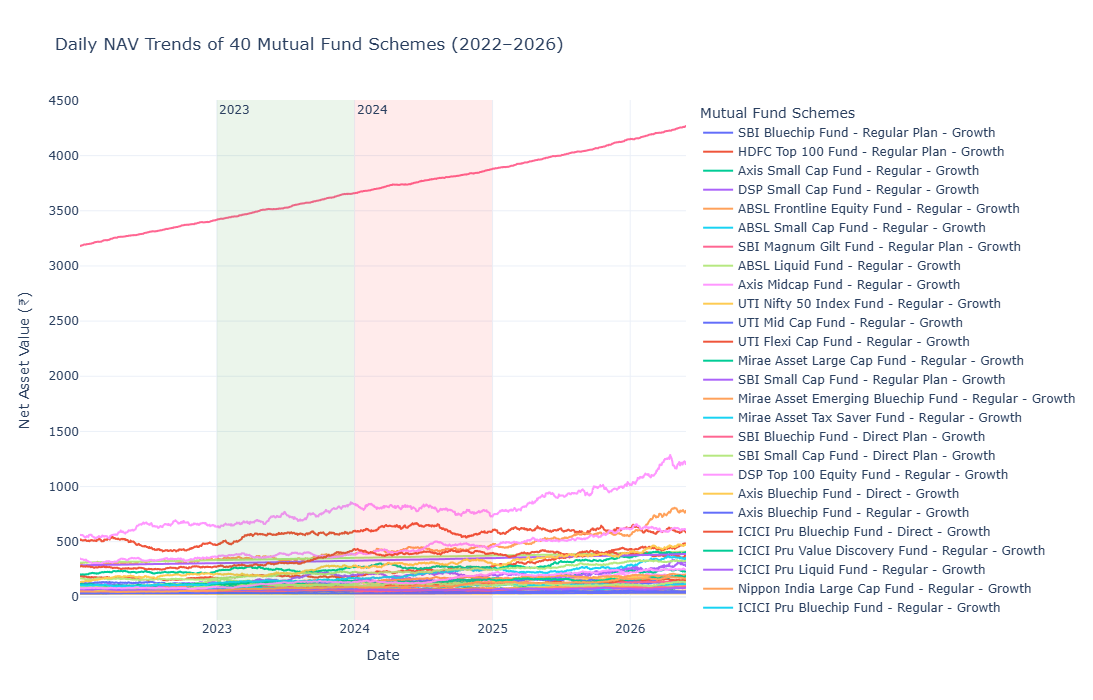

In [12]:
# Interactive NAV trend for all 40 mutual fund schemes

fig = px.line(
    nav_df,
    x="date",
    y="nav",
    color="scheme_name",
    title="Daily NAV Trends of 40 Mutual Fund Schemes (2022–2026)",
    labels={
        "date": "Date",
        "nav": "Net Asset Value (₹)",
        "scheme_name": "Mutual Fund Scheme"
    }
)

# Highlight 2023 period
fig.add_vrect(
    x0="2023-01-01",
    x1="2023-12-31",
    fillcolor="green",
    opacity=0.08,
    line_width=0,
    annotation_text="2023",
    annotation_position="top left"
)

# Highlight 2024 period
fig.add_vrect(
    x0="2024-01-01",
    x1="2024-12-31",
    fillcolor="red",
    opacity=0.08,
    line_width=0,
    annotation_text="2024",
    annotation_position="top left"
)

fig.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=700,
    legend_title="Mutual Fund Schemes"
)

fig.show()

In [12]:
# Export NAV chart as PNG

os.makedirs("reports/eda_charts", exist_ok=True)

fig.write_image("reports/eda_charts/01_nav_trends.png")

print("NAV chart exported successfully!")

RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


In [13]:
!pip install -U kaleido


   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------- ----------------------------- 1/4 [logistro]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   -------


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [1]:
os.makedirs("reports/eda_charts", exist_ok=True)

fig.write_image("reports/eda_charts/01_nav_trends.png")

print("NAV chart exported successfully!")

NameError: name 'os' is not defined

In [2]:
import sys
print("Python:", sys.executable)

import kaleido
print("Kaleido version:", kaleido.__version__)

Python: C:\Users\User\Documents\Bluestock_Mutual_Fund_Analytics\.venv\Scripts\python.exe


AttributeError: module 'kaleido' has no attribute '__version__'

In [3]:
import os

os.makedirs("reports/eda_charts", exist_ok=True)

fig.write_image("reports/eda_charts/01_nav_trends.png")

print("NAV chart exported successfully!")

NameError: name 'fig' is not defined

In [4]:
import sys
from importlib.metadata import version

print("Python:", sys.executable)
print("Kaleido version:", version("kaleido"))

Python: C:\Users\User\Documents\Bluestock_Mutual_Fund_Analytics\.venv\Scripts\python.exe
Kaleido version: 1.5.2


In [13]:
import os

os.makedirs("reports/eda_charts", exist_ok=True)

fig.write_image("reports/eda_charts/01_nav_trends.png")

print("NAV chart exported successfully!")

NAV chart exported successfully!


In [14]:
aum_df = datasets["aum"].copy()

print("AUM Dataset Shape:", aum_df.shape)
print("\nFund Houses:")
print(aum_df["fund_house"].unique())

print("\nSample Data:")
display(aum_df.head(10))

AUM Dataset Shape: (90, 5)

Fund Houses:
<StringArray>
[         'SBI Mutual Fund',      'ICICI Prudential MF',
         'HDFC Mutual Fund',          'Nippon India MF',
        'Kotak Mahindra MF', 'Aditya Birla Sun Life MF',
         'Axis Mutual Fund',          'UTI Mutual Fund',
           'Mirae Asset MF',          'DSP Mutual Fund']
Length: 10, dtype: str

Sample Data:


,date,fund_house,aum_lakh_crore,aum_crore,num_schemes
0,2022-03-31,SBI Mutual Fund,6.05,605000,186
1,2022-03-31,ICICI Prudential MF,4.65,465000,216
2,2022-03-31,HDFC Mutual Fund,4.35,435000,195
3,2022-03-31,Nippon India MF,2.70,270000,177
4,2022-03-31,Kotak Mahindra MF,2.70,270000,168
5,2022-03-31,Aditya Birla Sun Life MF,2.78,278000,199
6,2022-03-31,Axis Mutual Fund,2.50,250000,95
7,2022-03-31,UTI Mutual Fund,2.30,230000,142
8,2022-03-31,Mirae Asset MF,1.05,105000,56
9,2022-03-31,DSP Mutual Fund,1.10,110000,88


In [15]:
print("Available AUM dates:")
print(aum_df["date"].sort_values().unique())

print("\nRecords per year:")
print(aum_df.groupby(aum_df["date"].dt.year).size())

Available AUM dates:
<DatetimeArray>
['2022-03-31 00:00:00', '2022-09-30 00:00:00', '2023-03-31 00:00:00',
 '2023-09-30 00:00:00', '2024-03-31 00:00:00', '2024-09-30 00:00:00',
 '2024-12-31 00:00:00', '2025-03-31 00:00:00', '2025-12-31 00:00:00']
Length: 9, dtype: datetime64[us]

Records per year:
date
2022    20
2023    20
2024    30
2025    20
dtype: int64


In [16]:
# Select the latest AUM record for each fund house in each year

aum_df["year"] = aum_df["date"].dt.year

aum_yearly = (
    aum_df.sort_values("date")
    .groupby(["year", "fund_house"])
    .tail(1)
    .copy()
)

print("Selected AUM records:")
display(aum_yearly[["year", "fund_house", "aum_lakh_crore"]])

Selected AUM records:


,year,fund_house,aum_lakh_crore
19,2022,DSP Mutual Fund,1.12
18,2022,Mirae Asset MF,1.08
17,2022,UTI Mutual Fund,2.32
16,2022,Axis Mutual Fund,2.40
15,2022,Aditya Birla Sun Life MF,2.85
12,2022,HDFC Mutual Fund,4.45
13,2022,Nippon India MF,2.78
11,2022,ICICI Prudential MF,4.88
10,2022,SBI Mutual Fund,6.30
14,2022,Kotak Mahindra MF,2.72


In [17]:
# Select the latest AUM record for each fund house in each year

aum_df["year"] = aum_df["date"].dt.year

aum_yearly = (
    aum_df.sort_values("date")
    .groupby(["year", "fund_house"])
    .tail(1)
    .copy()
)

print("Selected AUM records:")
display(aum_yearly[["year", "fund_house", "aum_lakh_crore"]])

Selected AUM records:


,year,fund_house,aum_lakh_crore
19,2022,DSP Mutual Fund,1.12
18,2022,Mirae Asset MF,1.08
17,2022,UTI Mutual Fund,2.32
16,2022,Axis Mutual Fund,2.40
15,2022,Aditya Birla Sun Life MF,2.85
12,2022,HDFC Mutual Fund,4.45
13,2022,Nippon India MF,2.78
11,2022,ICICI Prudential MF,4.88
10,2022,SBI Mutual Fund,6.30
14,2022,Kotak Mahindra MF,2.72


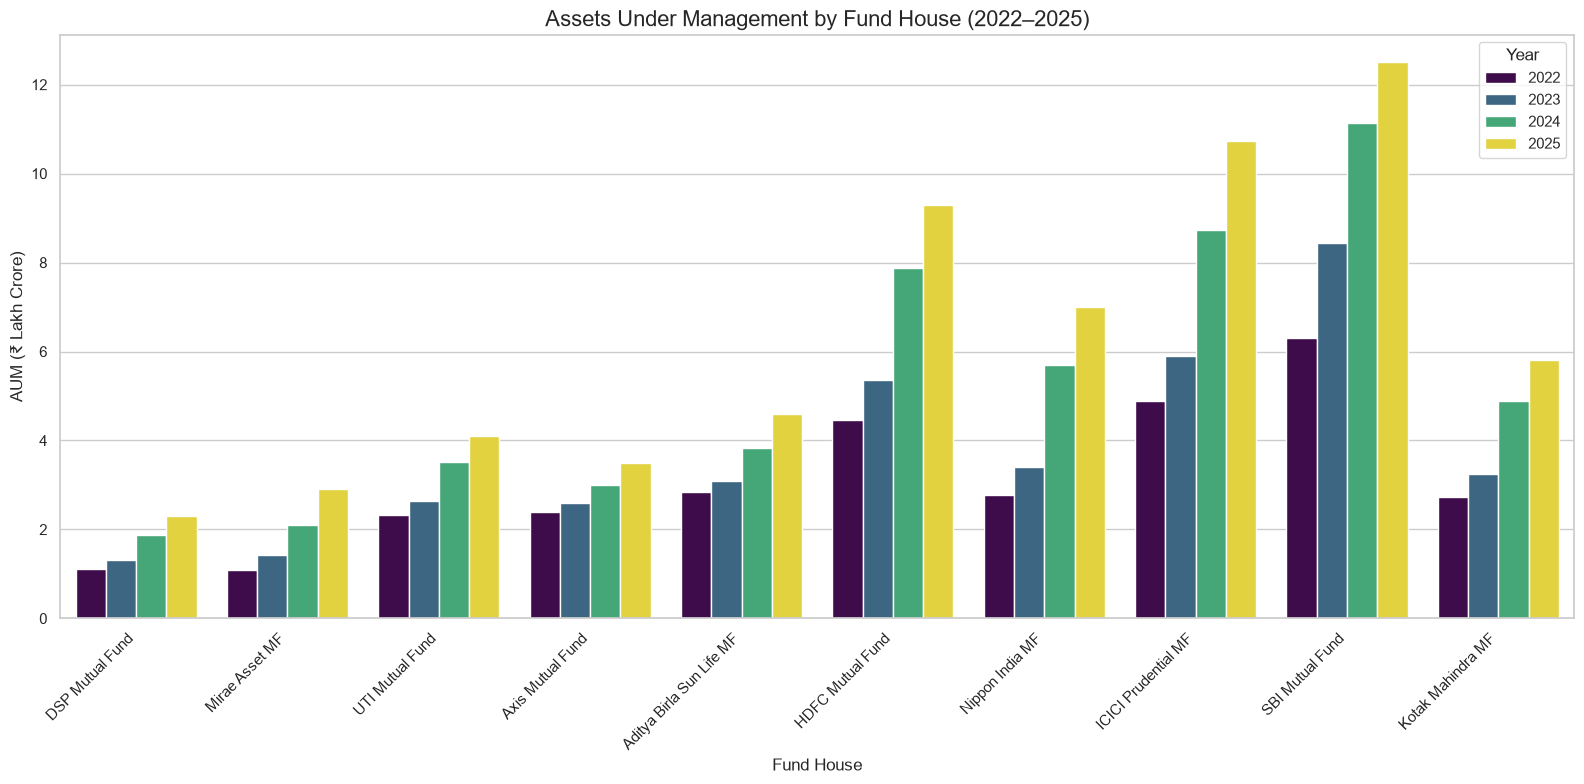

In [18]:
plt.figure(figsize=(16, 8))

sns.barplot(
    data=aum_yearly,
    x="fund_house",
    y="aum_lakh_crore",
    hue="year",
    palette="viridis"
)

plt.title("Assets Under Management by Fund House (2022–2025)", fontsize=16)
plt.xlabel("Fund House")
plt.ylabel("AUM (₹ Lakh Crore)")
plt.xticks(rotation=45, ha="right")
plt.legend(title="Year")
plt.tight_layout()

plt.show()

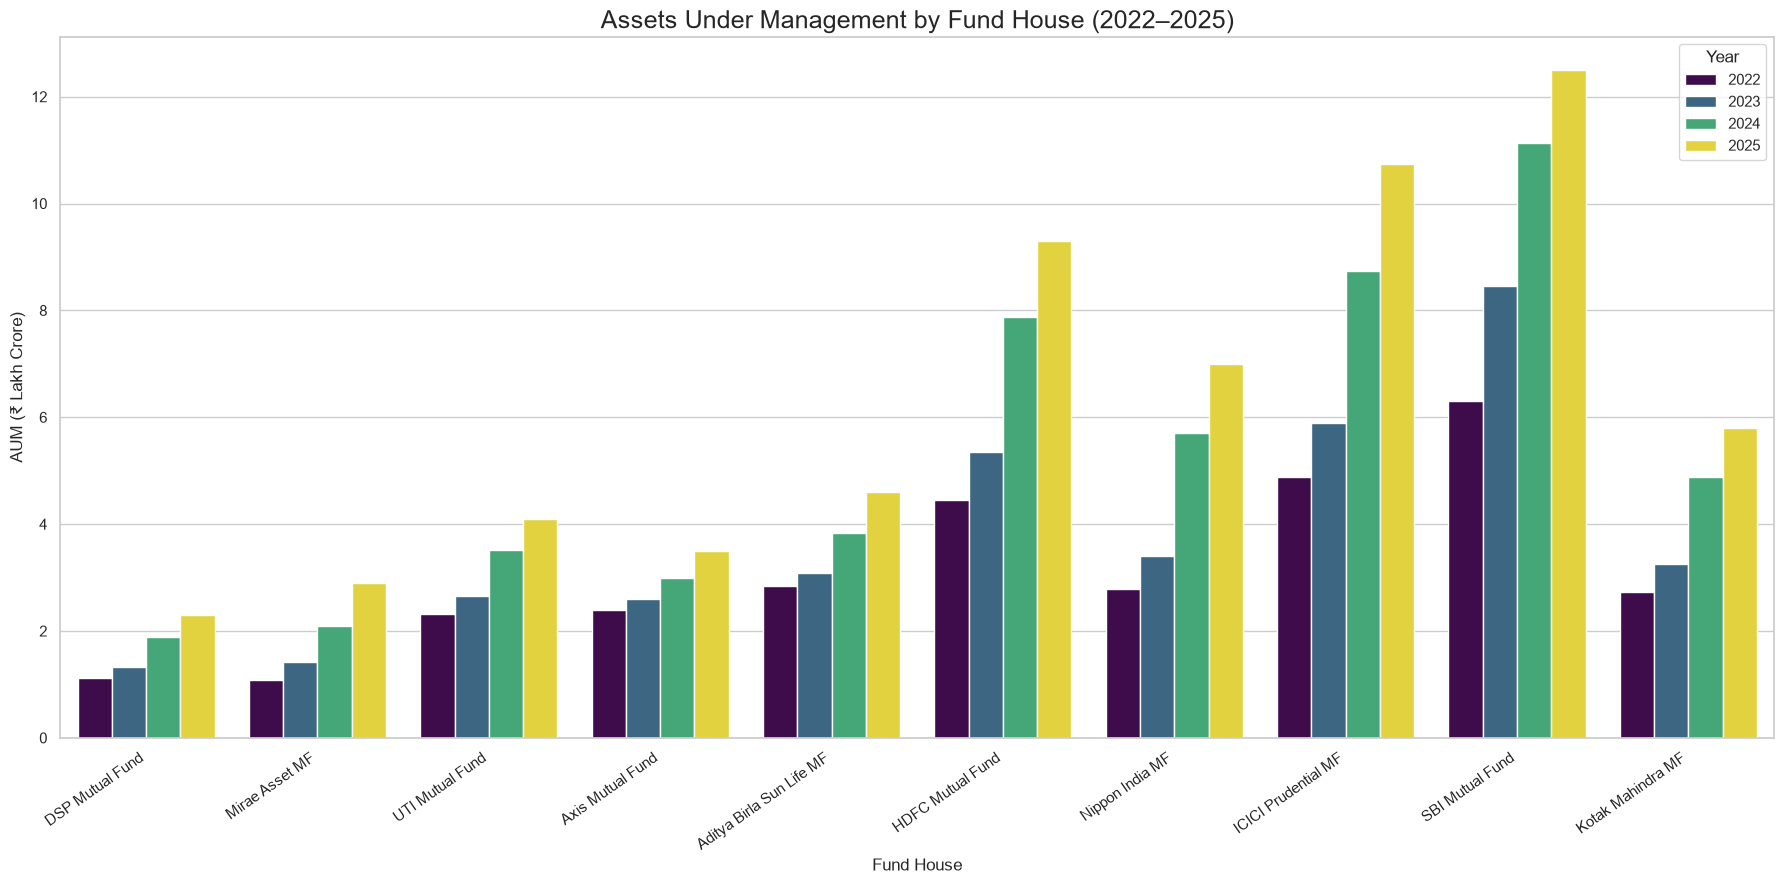

AUM chart exported successfully!


In [19]:
# AUM Growth by Fund House (2022–2025)

plt.figure(figsize=(18, 9))

sns.barplot(
    data=aum_yearly,
    x="fund_house",
    y="aum_lakh_crore",
    hue="year",
    palette="viridis"
)

plt.title("Assets Under Management by Fund House (2022–2025)", fontsize=18)
plt.xlabel("Fund House", fontsize=12)
plt.ylabel("AUM (₹ Lakh Crore)", fontsize=12)

plt.xticks(rotation=35, ha="right")
plt.legend(title="Year")
plt.tight_layout()

# Export chart
plt.savefig(
    "reports/eda_charts/02_aum_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("AUM chart exported successfully!")

In [20]:
sip_df = datasets["sip"].copy()

print("SIP Dataset Shape:", sip_df.shape)
print("\nColumns:", sip_df.columns.tolist())
print("\nDate Range:", sip_df["month"].min(), "to", sip_df["month"].max())

display(sip_df.head(10))

SIP Dataset Shape: (48, 6)

Columns: ['month', 'sip_inflow_crore', 'active_sip_accounts_crore', 'new_sip_accounts_lakh', 'sip_aum_lakh_crore', 'yoy_growth_pct']

Date Range: 2022-01-01 00:00:00 to 2025-12-01 00:00:00


,month,sip_inflow_crore,active_sip_accounts_crore,new_sip_accounts_lakh,sip_aum_lakh_crore,yoy_growth_pct
0,2022-01-01,11517,4.91,9.10,4.80,NaN
1,2022-02-01,11438,4.93,8.20,4.85,NaN
2,2022-03-01,12328,5.09,10.50,5.01,NaN
3,2022-04-01,11863,5.48,9.52,5.12,NaN
4,2022-05-01,12286,5.55,8.10,5.15,NaN
5,2022-06-01,12276,5.60,7.50,5.18,NaN
6,2022-07-01,12140,5.65,9.21,5.25,NaN
7,2022-08-01,12694,5.71,8.90,5.31,NaN
8,2022-09-01,12976,5.80,9.40,5.41,NaN
9,2022-10-01,13040,5.93,9.52,5.55,NaN


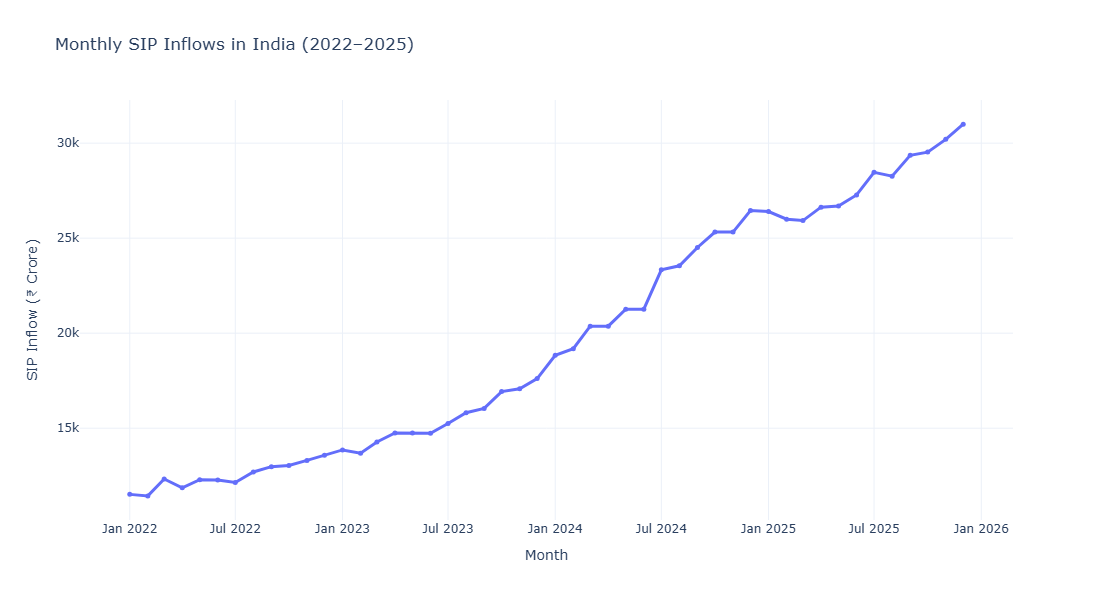

In [21]:
# Monthly SIP Inflow Trends (2022–2025)

fig_sip = px.line(
    sip_df,
    x="month",
    y="sip_inflow_crore",
    markers=True,
    title="Monthly SIP Inflows in India (2022–2025)",
    labels={
        "month": "Month",
        "sip_inflow_crore": "SIP Inflow (₹ Crore)"
    }
)

fig_sip.update_traces(
    line=dict(width=3),
    marker=dict(size=5)
)

fig_sip.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=600
)

fig_sip.show()

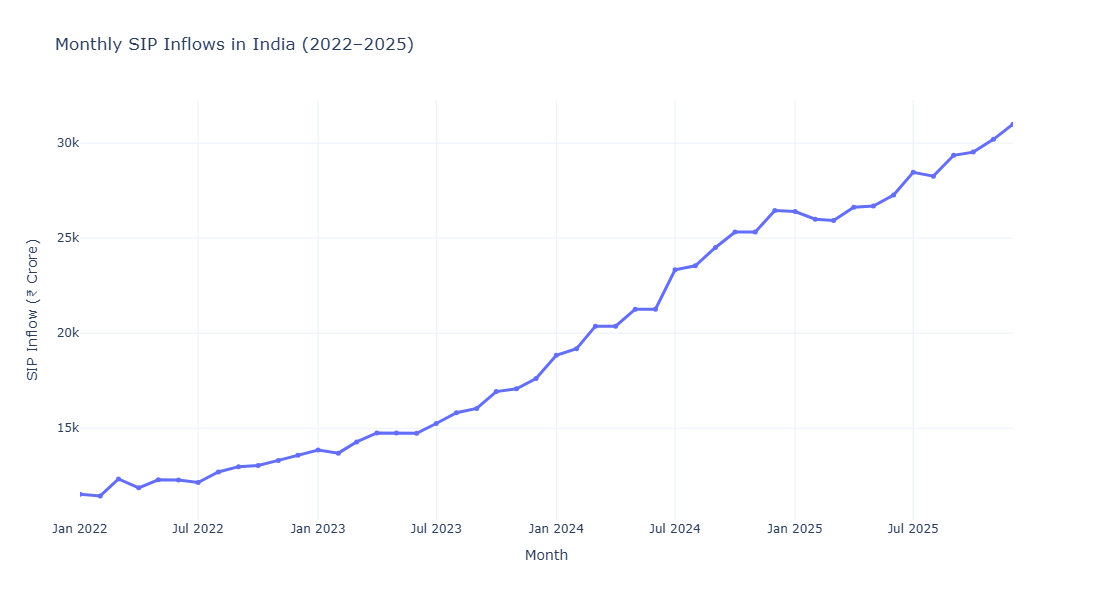

In [22]:
# Improve SIP chart layout

fig_sip.update_layout(
    template="plotly_white",
    hovermode="x unified",
    height=600,
    xaxis=dict(
        range=[sip_df["month"].min(), sip_df["month"].max()],
        title="Month"
    ),
    yaxis=dict(
        title="SIP Inflow (₹ Crore)"
    )
)

fig_sip.show()

In [23]:
fig_sip.write_image("reports/eda_charts/03_sip_inflow_trends.png")

print("SIP chart exported successfully!")

SIP chart exported successfully!


In [24]:
category_df = datasets["category_inflows"].copy()

print("Dataset Shape:", category_df.shape)
print("\nColumns:", category_df.columns.tolist())
print("\nDate Range:", category_df["month"].min(), "to", category_df["month"].max())
print("\nCategories:")
print(category_df["category"].unique())

display(category_df.head(10))

Dataset Shape: (144, 3)

Columns: ['month', 'category', 'net_inflow_crore']

Date Range: 2024-04-01 00:00:00 to 2025-03-01 00:00:00

Categories:
<StringArray>
[        'Large Cap',           'Mid Cap',         'Small Cap',
         'Flexi Cap',   'Large & Mid Cap',              'ELSS',
      'Value/Contra', 'Sectoral/Thematic',            'Liquid',
    'Short Duration',              'Gilt',            'Hybrid']
Length: 12, dtype: str


,month,category,net_inflow_crore
0,2024-04-01,Large Cap,2413.0
1,2024-04-01,Mid Cap,3897.0
2,2024-04-01,Small Cap,3533.0
3,2024-04-01,Flexi Cap,4947.0
4,2024-04-01,Large & Mid Cap,4214.0
5,2024-04-01,ELSS,466.0
6,2024-04-01,Value/Contra,1328.0
7,2024-04-01,Sectoral/Thematic,8052.0
8,2024-04-01,Liquid,37537.0
9,2024-04-01,Short Duration,4400.0


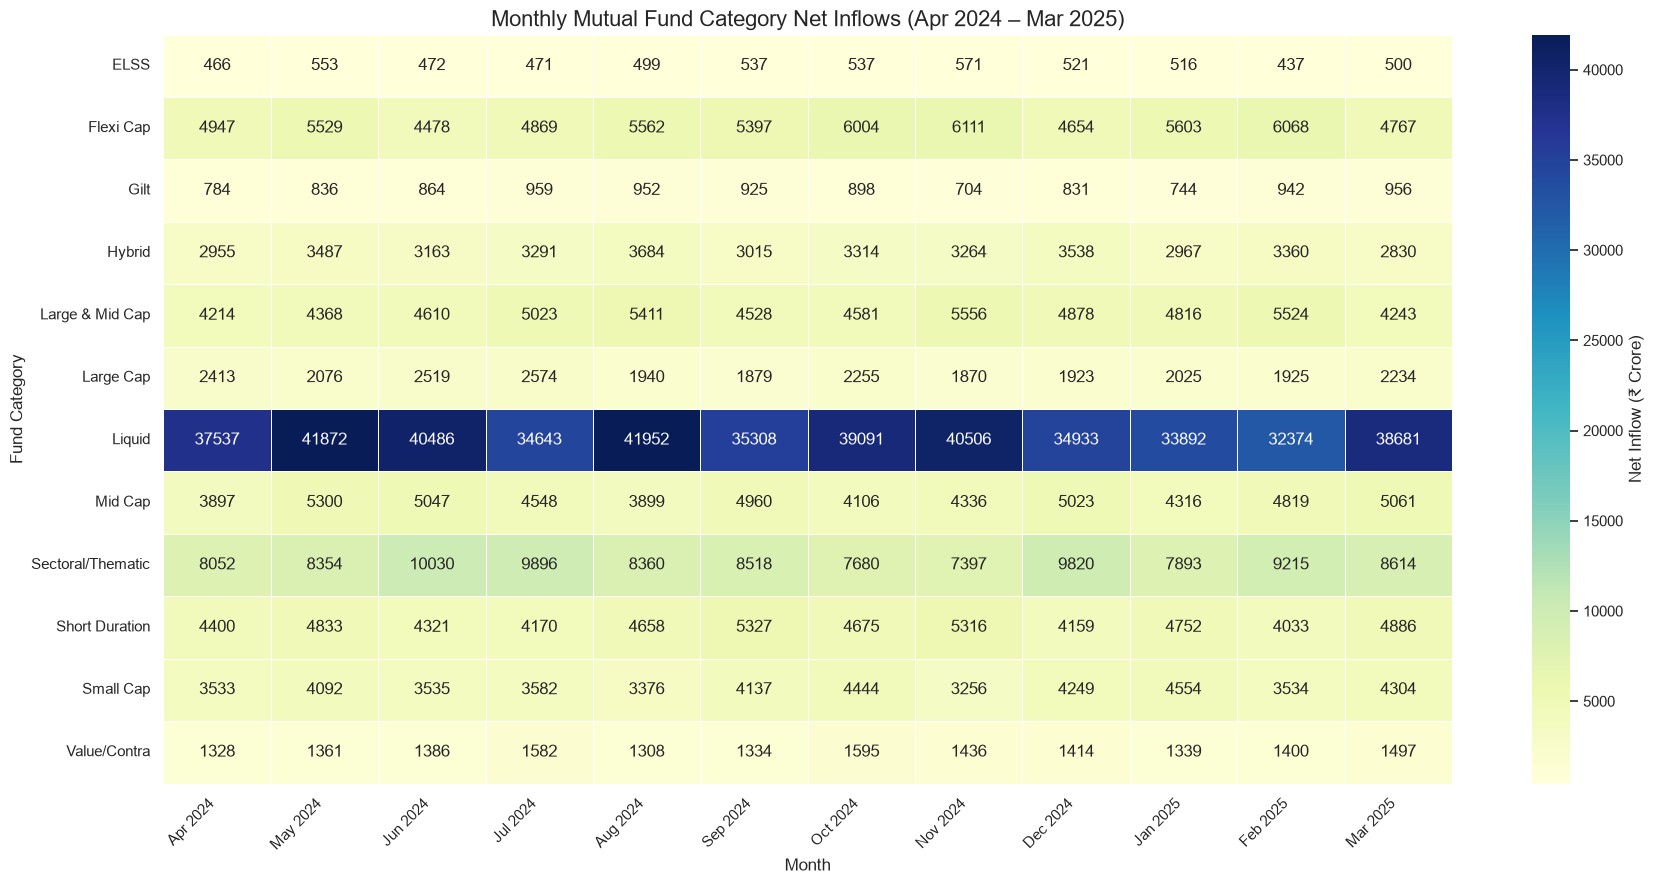

In [25]:
# Category-wise Monthly Net Inflow Heatmap

category_pivot = category_df.pivot(
    index="category",
    columns="month",
    values="net_inflow_crore"
)

# Format month labels
category_pivot.columns = category_pivot.columns.strftime("%b %Y")

plt.figure(figsize=(18, 9))

sns.heatmap(
    category_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Monthly Mutual Fund Category Net Inflows (Apr 2024 – Mar 2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Fund Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.show()

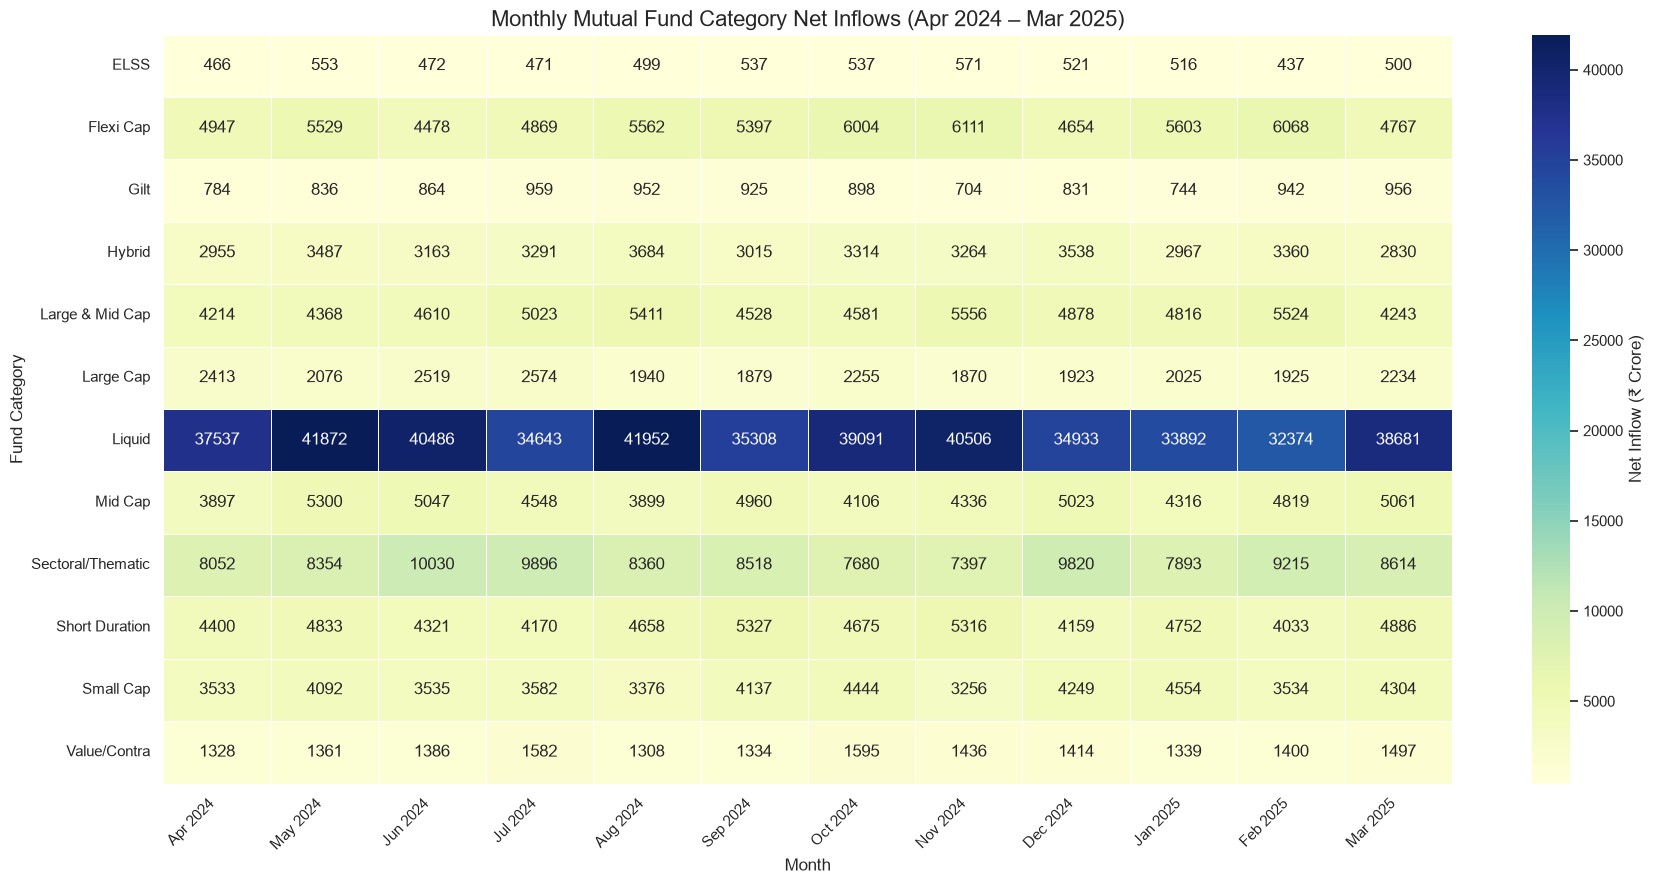

Category inflow heatmap exported successfully!


In [26]:
plt.figure(figsize=(18, 9))

sns.heatmap(
    category_pivot,
    annot=True,
    fmt=".0f",
    cmap="YlGnBu",
    linewidths=0.5,
    cbar_kws={"label": "Net Inflow (₹ Crore)"}
)

plt.title("Monthly Mutual Fund Category Net Inflows (Apr 2024 – Mar 2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Fund Category")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/04_category_inflow_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Category inflow heatmap exported successfully!")

In [27]:
# Investor Demographics Analysis

investor_df = datasets["transactions"].copy()

print("Investor Dataset Shape:", investor_df.shape)
print("\nAge Groups:")
print(investor_df["age_group"].value_counts())

print("\nGender Distribution:")
print(investor_df["gender"].value_counts())

print("\nTransaction Amount Summary:")
print(investor_df["amount_inr"].describe())

Investor Dataset Shape: (32778, 13)

Age Groups:
age_group
26-35    13463
36-45     8146
18-25     4916
46-55     3779
56+       2474
Name: count, dtype: int64

Gender Distribution:
gender
Male      21809
Female    10969
Name: count, dtype: int64

Transaction Amount Summary:
count     32778.000000
mean     107437.318628
std      150415.905084
min         400.000000
25%        3153.000000
50%       17782.500000
75%      189324.250000
max      597498.000000
Name: amount_inr, dtype: float64


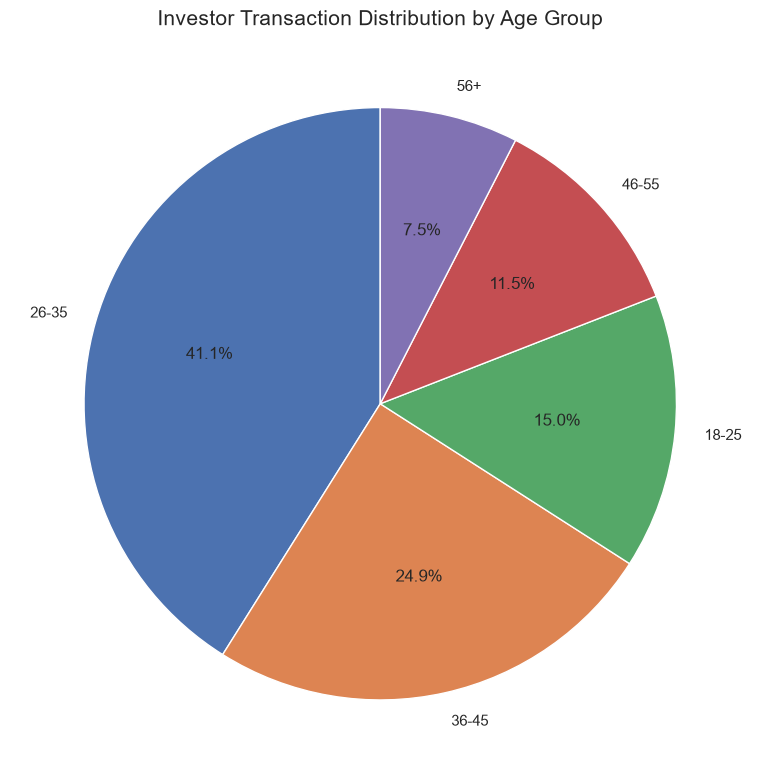

In [28]:
# Transaction Distribution by Age Group

age_counts = investor_df["age_group"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Transaction Distribution by Age Group", fontsize=15)
plt.tight_layout()

plt.show()

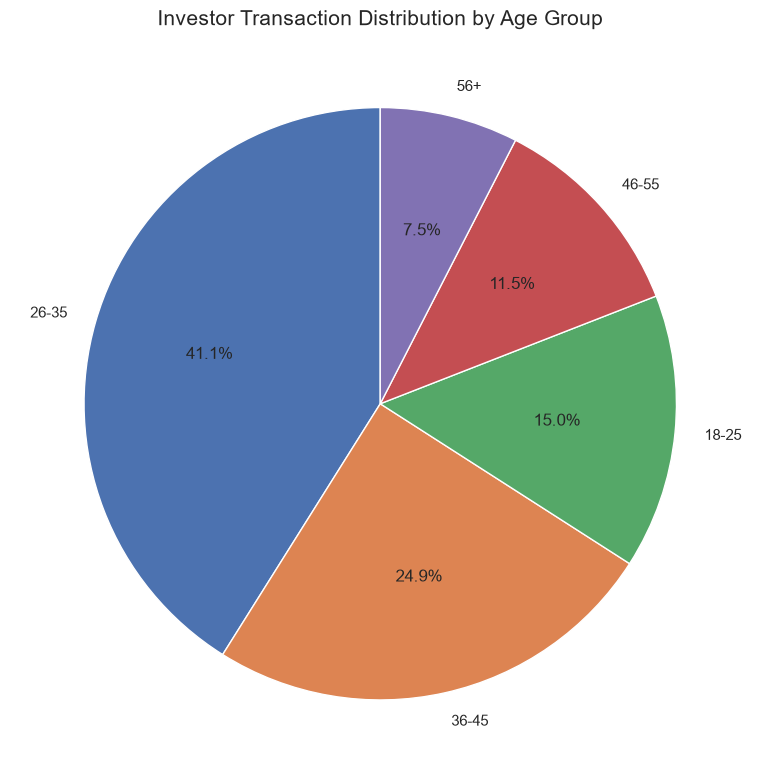

Age distribution chart exported successfully!


In [29]:
plt.figure(figsize=(8, 8))

plt.pie(
    age_counts,
    labels=age_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Transaction Distribution by Age Group", fontsize=15)
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/05_age_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Age distribution chart exported successfully!")

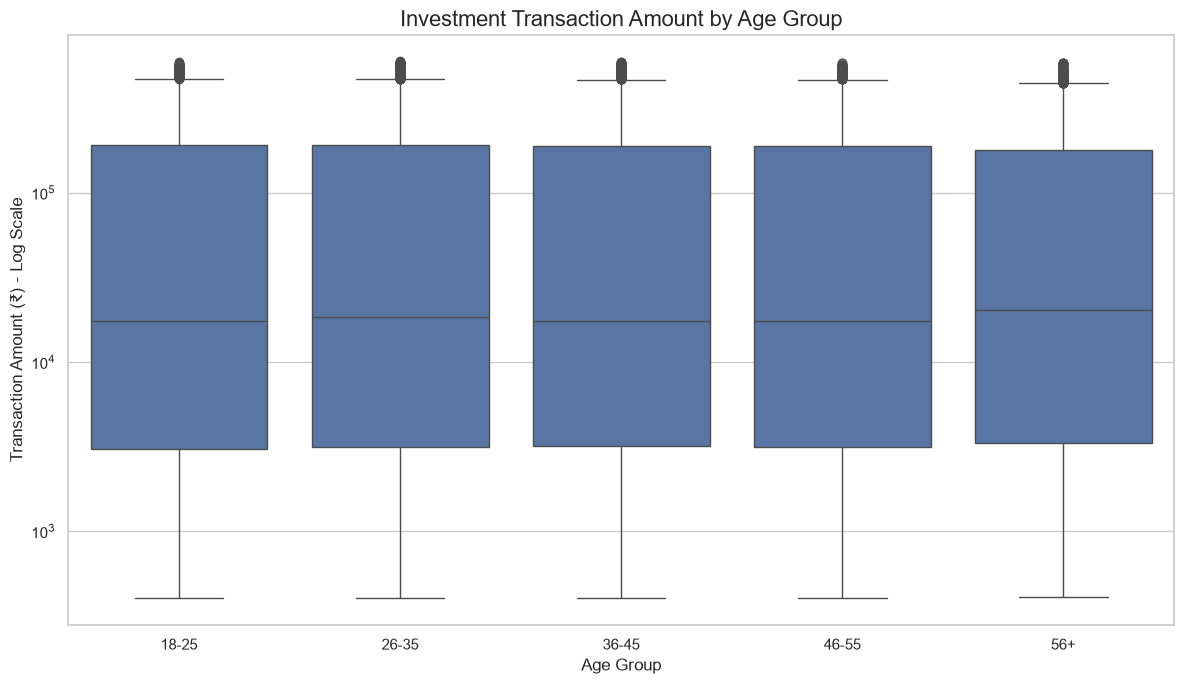

In [30]:
# Investment Transaction Amount by Age Group

age_order = ["18-25", "26-35", "36-45", "46-55", "56+"]

plt.figure(figsize=(12, 7))

sns.boxplot(
    data=investor_df,
    x="age_group",
    y="amount_inr",
    order=age_order
)

plt.yscale("log")

plt.title("Investment Transaction Amount by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Transaction Amount (₹) - Log Scale")

plt.tight_layout()
plt.show()

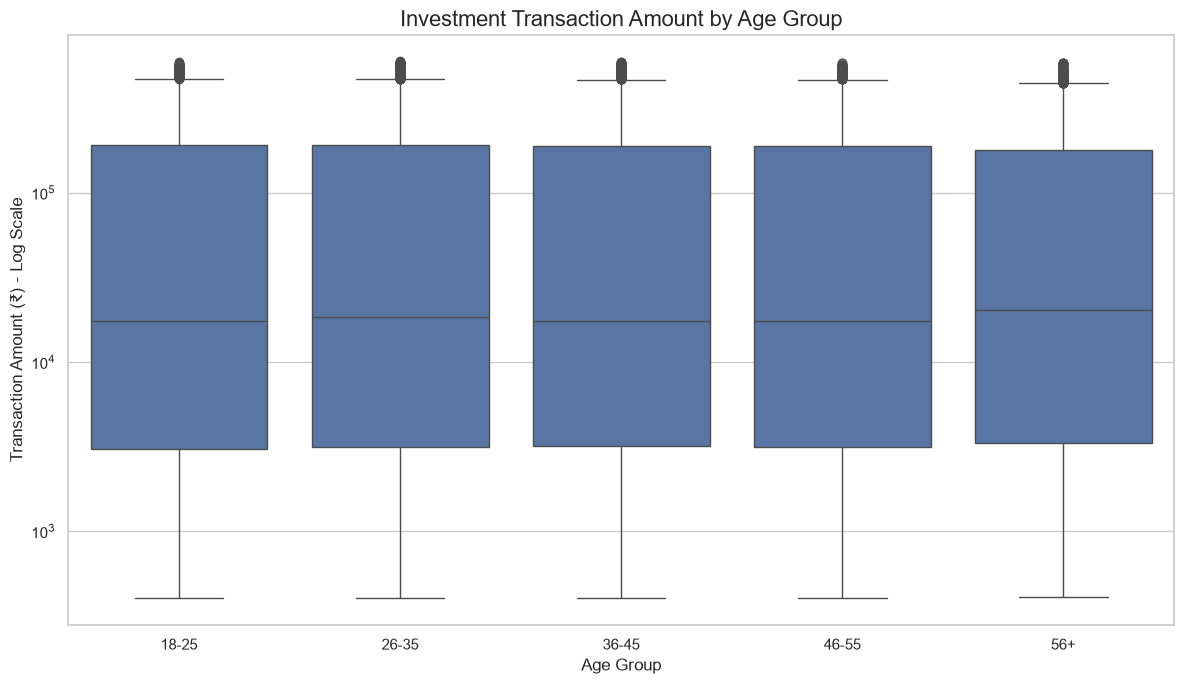

Investment by age chart exported successfully!


In [31]:
plt.figure(figsize=(12, 7))

sns.boxplot(
    data=investor_df,
    x="age_group",
    y="amount_inr",
    order=age_order
)

plt.yscale("log")
plt.title("Investment Transaction Amount by Age Group", fontsize=16)
plt.xlabel("Age Group")
plt.ylabel("Transaction Amount (₹) - Log Scale")
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/06_investment_by_age.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Investment by age chart exported successfully!")

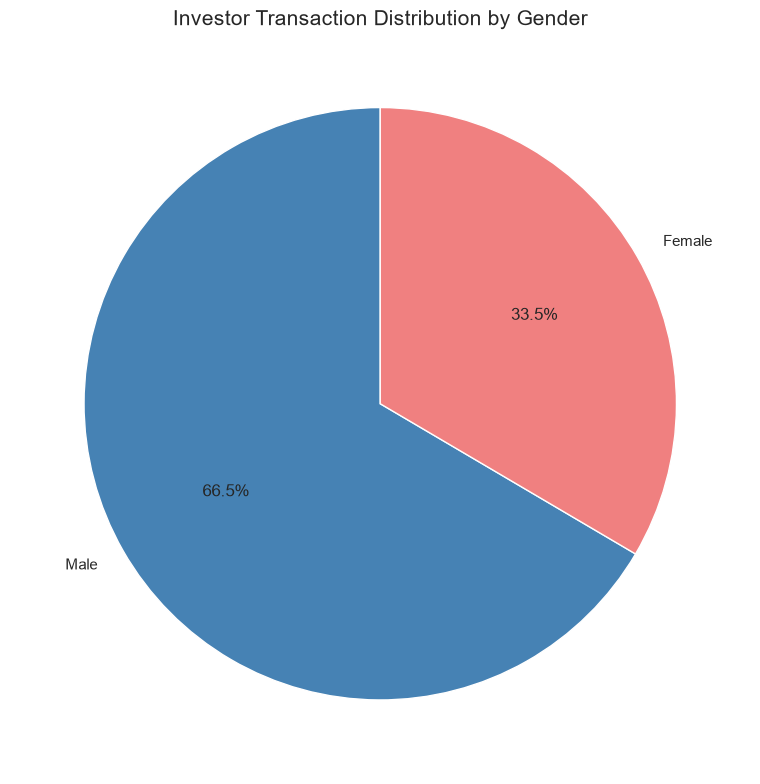

In [32]:
# Transaction Distribution by Gender

gender_counts = investor_df["gender"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "lightcoral"],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Transaction Distribution by Gender", fontsize=15)
plt.tight_layout()

plt.show()

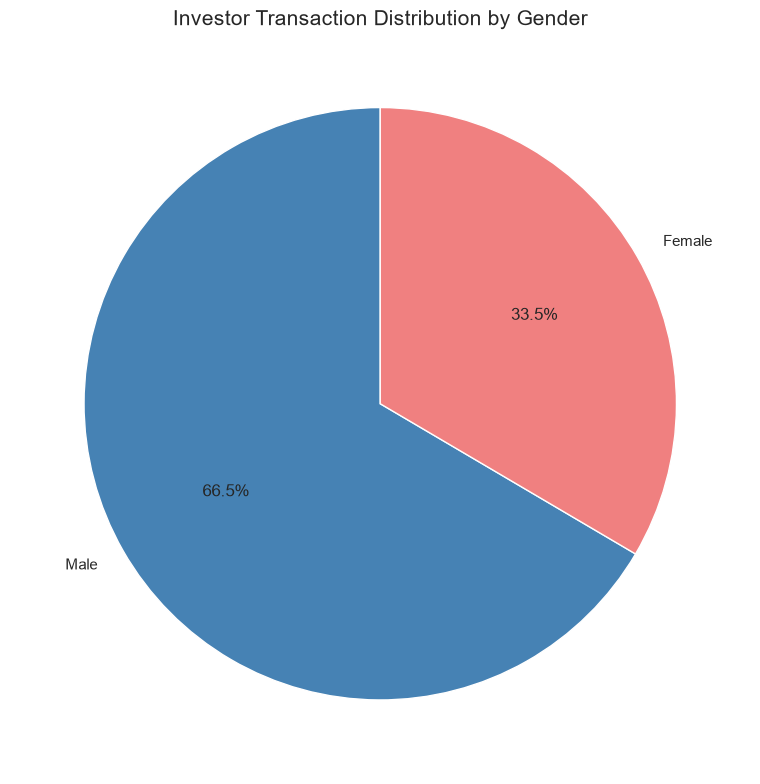

Gender distribution chart exported successfully!


In [33]:
plt.figure(figsize=(8, 8))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "lightcoral"],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Transaction Distribution by Gender", fontsize=15)
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/07_gender_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Gender distribution chart exported successfully!")

In [34]:
# Geographic Analysis

print("Available States:", investor_df["state"].nunique())
print("\nState-wise transaction count:")
print(investor_df["state"].value_counts())

print("\nCity Tier Distribution:")
print(investor_df["city_tier"].value_counts())

print("\nTransaction Amount by State:")
display(
    investor_df.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=False)
)

Available States: 12

State-wise transaction count:
state
Punjab            2965
Madhya Pradesh    2931
Tamil Nadu        2806
Gujarat           2780
West Bengal       2748
Haryana           2736
Telangana         2718
Uttar Pradesh     2695
Delhi             2677
Karnataka         2621
Rajasthan         2577
Maharashtra       2524
Name: count, dtype: int64

City Tier Distribution:
city_tier
T30    21719
B30    11059
Name: count, dtype: int64

Transaction Amount by State:


state
Punjab            315780459
Tamil Nadu        315177237
Madhya Pradesh    308312493
Rajasthan         298645822
Gujarat           298358940
West Bengal       297182514
Telangana         290219284
Delhi             289633404
Uttar Pradesh     285368873
Haryana           279634354
Karnataka         273753570
Maharashtra       269513480
Name: amount_inr, dtype: int64

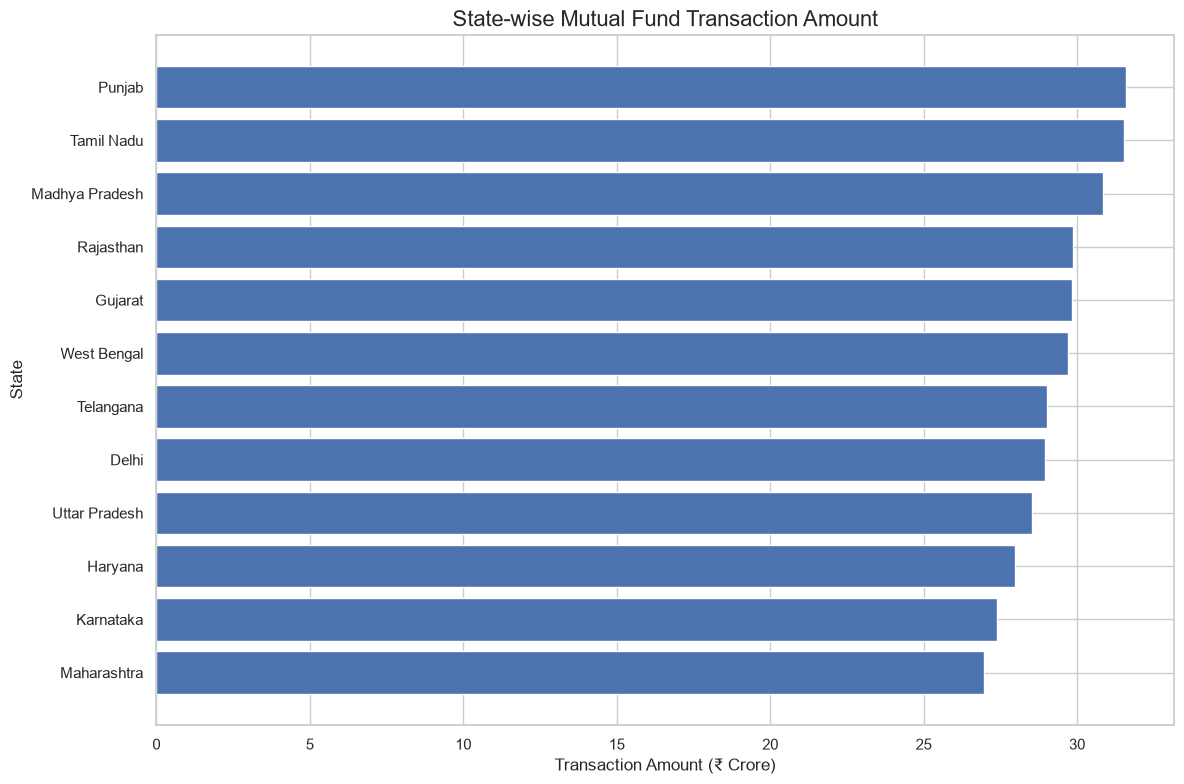

In [35]:
# State-wise Total Transaction Amount

state_amounts = (
    investor_df.groupby("state")["amount_inr"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 8))

plt.barh(
    state_amounts.index,
    state_amounts.values / 1e7
)

plt.title("State-wise Mutual Fund Transaction Amount", fontsize=16)
plt.xlabel("Transaction Amount (₹ Crore)")
plt.ylabel("State")

plt.tight_layout()
plt.show()

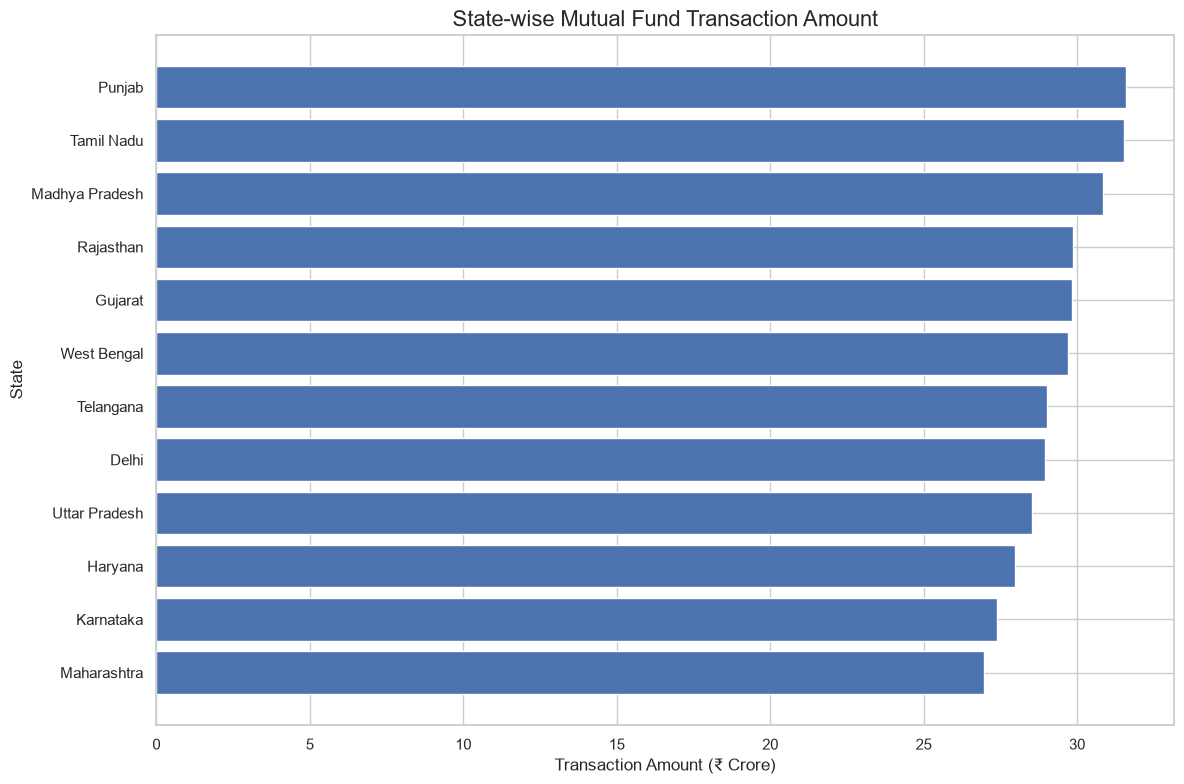

State-wise investment chart exported successfully!


In [36]:
plt.figure(figsize=(12, 8))

plt.barh(
    state_amounts.index,
    state_amounts.values / 1e7
)

plt.title("State-wise Mutual Fund Transaction Amount", fontsize=16)
plt.xlabel("Transaction Amount (₹ Crore)")
plt.ylabel("State")
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/08_statewise_investment.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("State-wise investment chart exported successfully!")

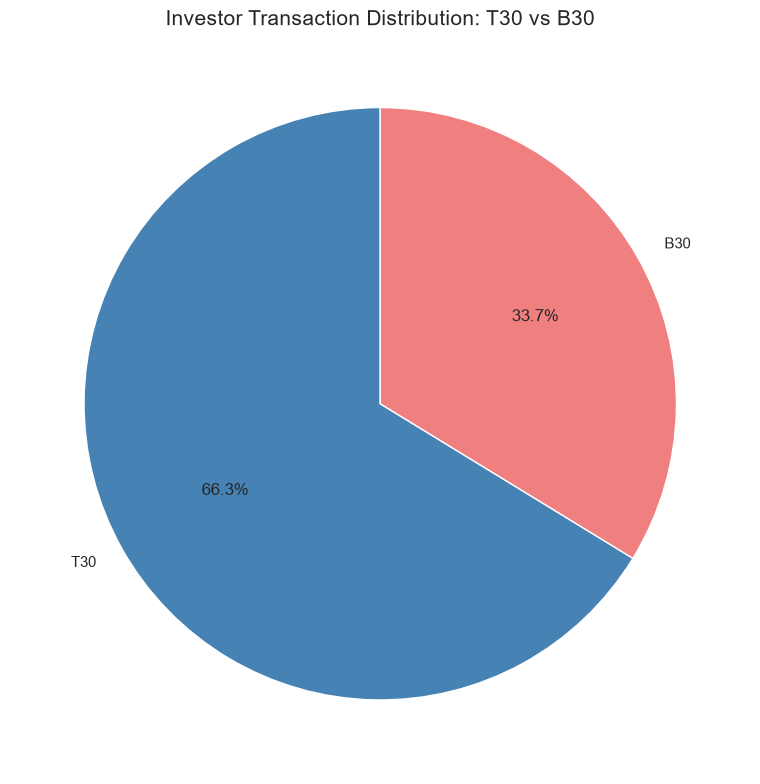

In [37]:
# Transaction Distribution by City Tier

tier_counts = investor_df["city_tier"].value_counts()

plt.figure(figsize=(8, 8))

plt.pie(
    tier_counts,
    labels=tier_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "lightcoral"],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Transaction Distribution: T30 vs B30", fontsize=15)
plt.tight_layout()

plt.show()

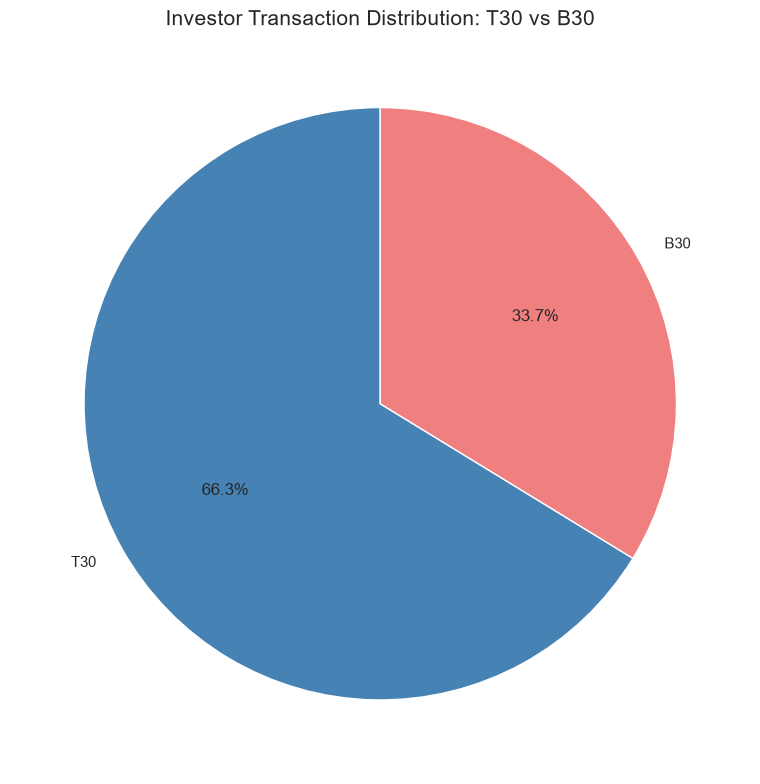

City tier chart exported successfully!


In [38]:
plt.figure(figsize=(8, 8))

plt.pie(
    tier_counts,
    labels=tier_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=["steelblue", "lightcoral"],
    wedgeprops={"edgecolor": "white"}
)

plt.title("Investor Transaction Distribution: T30 vs B30", fontsize=15)
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/09_city_tier_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("City tier chart exported successfully!")

In [39]:
folio_df = datasets["folio"].copy()

print("Folio Dataset Shape:", folio_df.shape)
print("\nColumns:", folio_df.columns.tolist())
print("\nDate Range:", folio_df["month"].min(), "to", folio_df["month"].max())

display(folio_df.head(10))

Folio Dataset Shape: (21, 6)

Columns: ['month', 'total_folios_crore', 'equity_folios_crore', 'debt_folios_crore', 'hybrid_folios_crore', 'others_folios_crore']

Date Range: 2022-01-01 00:00:00 to 2025-12-01 00:00:00


,month,total_folios_crore,equity_folios_crore,debt_folios_crore,hybrid_folios_crore,others_folios_crore
0,2022-01-01,13.26,9.28,1.86,0.80,1.33
1,2022-04-01,13.91,9.74,1.95,0.83,1.39
2,2022-07-01,13.85,9.69,1.94,0.83,1.38
3,2022-10-01,14.12,9.88,1.98,0.85,1.41
4,2023-01-01,14.81,10.37,2.07,0.89,1.48
5,2023-04-01,15.54,10.88,2.18,0.93,1.55
6,2023-07-01,16.28,11.40,2.28,0.98,1.63
7,2023-10-01,16.72,11.70,2.34,1.00,1.67
8,2024-01-01,17.78,12.45,2.49,1.07,1.78
9,2024-04-01,18.85,13.20,2.64,1.13,1.89


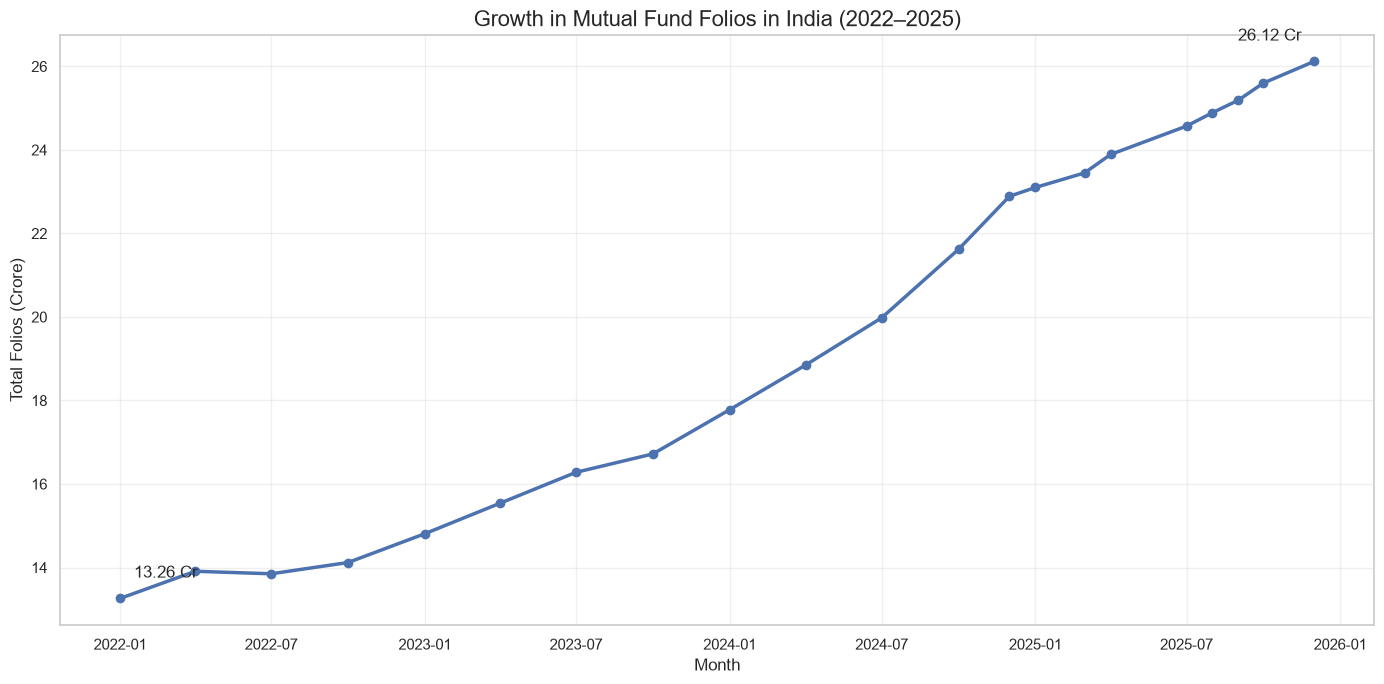

In [40]:
# Total Mutual Fund Folio Growth (2022–2025)

plt.figure(figsize=(14, 7))

plt.plot(
    folio_df["month"],
    folio_df["total_folios_crore"],
    marker="o",
    linewidth=2.5,
    markersize=6
)

# Highlight starting and ending values
plt.annotate(
    f'{folio_df["total_folios_crore"].iloc[0]:.2f} Cr',
    (folio_df["month"].iloc[0], folio_df["total_folios_crore"].iloc[0]),
    xytext=(10, 15),
    textcoords="offset points"
)

plt.annotate(
    f'{folio_df["total_folios_crore"].iloc[-1]:.2f} Cr',
    (folio_df["month"].iloc[-1], folio_df["total_folios_crore"].iloc[-1]),
    xytext=(-55, 15),
    textcoords="offset points"
)

plt.title("Growth in Mutual Fund Folios in India (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.show()

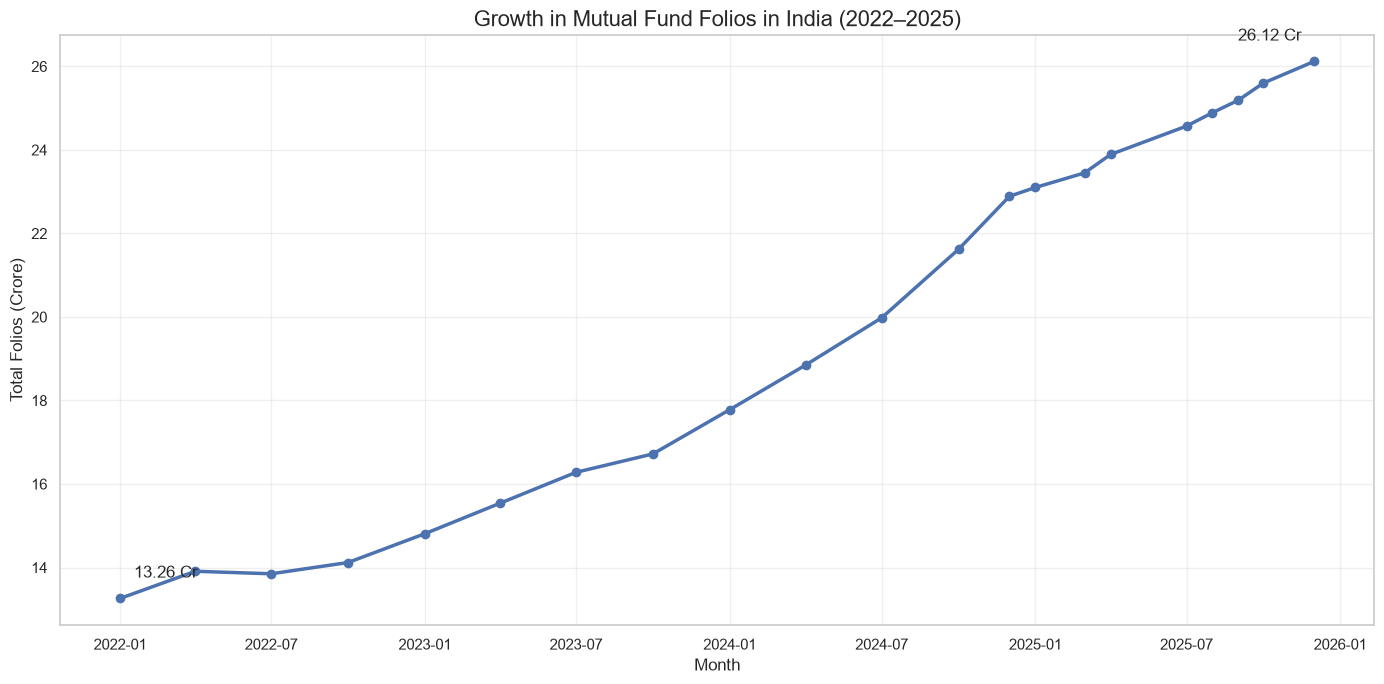

Folio growth chart exported successfully!


In [41]:
plt.figure(figsize=(14, 7))

plt.plot(
    folio_df["month"],
    folio_df["total_folios_crore"],
    marker="o",
    linewidth=2.5,
    markersize=6
)

plt.annotate(
    f'{folio_df["total_folios_crore"].iloc[0]:.2f} Cr',
    (folio_df["month"].iloc[0], folio_df["total_folios_crore"].iloc[0]),
    xytext=(10, 15),
    textcoords="offset points"
)

plt.annotate(
    f'{folio_df["total_folios_crore"].iloc[-1]:.2f} Cr',
    (folio_df["month"].iloc[-1], folio_df["total_folios_crore"].iloc[-1]),
    xytext=(-55, 15),
    textcoords="offset points"
)

plt.title("Growth in Mutual Fund Folios in India (2022–2025)", fontsize=16)
plt.xlabel("Month")
plt.ylabel("Total Folios (Crore)")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    "reports/eda_charts/10_folio_growth.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Folio growth chart exported successfully!")

In [42]:
# Available mutual fund schemes

scheme_list = (
    datasets["fund_master"][["amfi_code", "scheme_name", "category"]]
    .drop_duplicates()
    .sort_values("scheme_name")
)

display(scheme_list.head(20))

,amfi_code,scheme_name,category
28,101206,ABSL Frontline Equity Fund - Regular - Growth,Equity
30,101208,ABSL Liquid Fund - Regular - Growth,Debt
29,101207,ABSL Small Cap Fund - Regular - Growth,Equity
25,119093,Axis Bluechip Fund - Direct - Growth,Equity
24,119092,Axis Bluechip Fund - Regular - Growth,Equity
26,119094,Axis Midcap Fund - Regular - Growth,Equity
27,119095,Axis Small Cap Fund - Regular - Growth,Equity
38,149323,DSP Midcap Fund - Regular - Growth,Equity
39,149324,DSP Small Cap Fund - Regular - Growth,Equity
37,149322,DSP Top 100 Equity Fund - Regular - Growth,Equity


In [43]:
# Select 10 equity mutual fund schemes

selected_schemes = [
    "ABSL Frontline Equity Fund - Regular - Growth",
    "ABSL Small Cap Fund - Regular - Growth",
    "Axis Bluechip Fund - Regular - Growth",
    "Axis Midcap Fund - Regular - Growth",
    "Axis Small Cap Fund - Regular - Growth",
    "DSP Midcap Fund - Regular - Growth",
    "DSP Small Cap Fund - Regular - Growth",
    "DSP Top 100 Equity Fund - Regular - Growth",
    "HDFC Mid-Cap Opportunities Fund - Regular - Growth",
    "HDFC Top 100 Fund - Regular Plan - Growth"
]

# Filter NAV data for the selected schemes
correlation_nav = nav_df[
    nav_df["scheme_name"].isin(selected_schemes)
].copy()

print("Selected schemes found:", correlation_nav["scheme_name"].nunique())
print("NAV records:", correlation_nav.shape)

display(
    correlation_nav[["date", "scheme_name", "nav"]].head(10)
)

Selected schemes found: 10
NAV records: (11500, 4)


,date,scheme_name,nav
5750,2022-01-03,HDFC Top 100 Fund - Regular Plan - Growth,520.4608
31050,2022-01-03,Axis Small Cap Fund - Regular - Growth,52.5238
44850,2022-01-03,DSP Small Cap Fund - Regular - Growth,81.6814
32200,2022-01-03,ABSL Frontline Equity Fund - Regular - Growth,305.0996
33350,2022-01-03,ABSL Small Cap Fund - Regular - Growth,38.5736
29900,2022-01-03,Axis Midcap Fund - Regular - Growth,68.3023
42550,2022-01-03,DSP Top 100 Equity Fund - Regular - Growth,348.7159
27600,2022-01-03,Axis Bluechip Fund - Regular - Growth,38.7466
8050,2022-01-03,HDFC Mid-Cap Opportunities Fund - Regular - Gr...,107.3758
43700,2022-01-03,DSP Midcap Fund - Regular - Growth,78.4622


In [44]:
# Convert NAV data into a wide format
nav_pivot = correlation_nav.pivot(
    index="date",
    columns="scheme_name",
    values="nav"
)

# Calculate daily percentage returns
daily_returns = nav_pivot.pct_change(fill_method=None)

print("Returns dataset shape:", daily_returns.shape)
display(daily_returns.head())

Returns dataset shape: (1150, 10)


scheme_name,ABSL Frontline Equity Fund - Regular - Growth,ABSL Small Cap Fund - Regular - Growth,Axis Bluechip Fund - Regular - Growth,Axis Midcap Fund - Regular - Growth,Axis Small Cap Fund - Regular - Growth,DSP Midcap Fund - Regular - Growth,DSP Small Cap Fund - Regular - Growth,DSP Top 100 Equity Fund - Regular - Growth,HDFC Mid-Cap Opportunities Fund - Regular - Growth,HDFC Top 100 Fund - Regular Plan - Growth
date,,,,,,,,,,
2022-01-03,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2022-01-04,0.001153,-0.010865,-0.006561,-0.003597,0.018757,0.000482,-0.010498,-0.008592,-0.013328,-0.010306
2022-01-05,0.003866,0.000603,-0.007511,0.016595,0.019898,0.008670,-0.002593,-0.006480,-0.004386,0.012865
2022-01-06,-0.002128,-0.029101,0.009926,-0.000246,-0.000431,-0.013861,-0.008382,-0.003818,-0.005167,-0.011377
2022-01-07,-0.006314,0.024766,0.009331,-0.018524,0.032482,0.004317,0.011680,-0.004069,-0.005748,-0.001210


In [45]:
# Calculate correlation between daily returns of the 10 funds

correlation_matrix = daily_returns.corr()

print("Correlation matrix calculated successfully!")
display(correlation_matrix.round(2))

Correlation matrix calculated successfully!


scheme_name,ABSL Frontline Equity Fund - Regular - Growth,ABSL Small Cap Fund - Regular - Growth,Axis Bluechip Fund - Regular - Growth,Axis Midcap Fund - Regular - Growth,Axis Small Cap Fund - Regular - Growth,DSP Midcap Fund - Regular - Growth,DSP Small Cap Fund - Regular - Growth,DSP Top 100 Equity Fund - Regular - Growth,HDFC Mid-Cap Opportunities Fund - Regular - Growth,HDFC Top 100 Fund - Regular Plan - Growth
scheme_name,,,,,,,,,,
ABSL Frontline Equity Fund - Regular - Growth,1.00,0.01,0.06,-0.04,-0.03,-0.00,-0.00,0.02,-0.02,0.03
ABSL Small Cap Fund - Regular - Growth,0.01,1.00,0.01,0.02,-0.03,0.01,-0.01,0.02,0.00,0.02
Axis Bluechip Fund - Regular - Growth,0.06,0.01,1.00,0.02,0.04,-0.02,0.01,0.02,0.07,0.01
Axis Midcap Fund - Regular - Growth,-0.04,0.02,0.02,1.00,-0.01,-0.02,-0.02,0.04,0.01,-0.07
Axis Small Cap Fund - Regular - Growth,-0.03,-0.03,0.04,-0.01,1.00,-0.01,-0.00,0.03,-0.04,-0.04
DSP Midcap Fund - Regular - Growth,-0.00,0.01,-0.02,-0.02,-0.01,1.00,0.01,-0.03,0.02,-0.01
DSP Small Cap Fund - Regular - Growth,-0.00,-0.01,0.01,-0.02,-0.00,0.01,1.00,0.00,-0.06,0.03
DSP Top 100 Equity Fund - Regular - Growth,0.02,0.02,0.02,0.04,0.03,-0.03,0.00,1.00,-0.05,0.04
HDFC Mid-Cap Opportunities Fund - Regular - Growth,-0.02,0.00,0.07,0.01,-0.04,0.02,-0.06,-0.05,1.00,-0.00


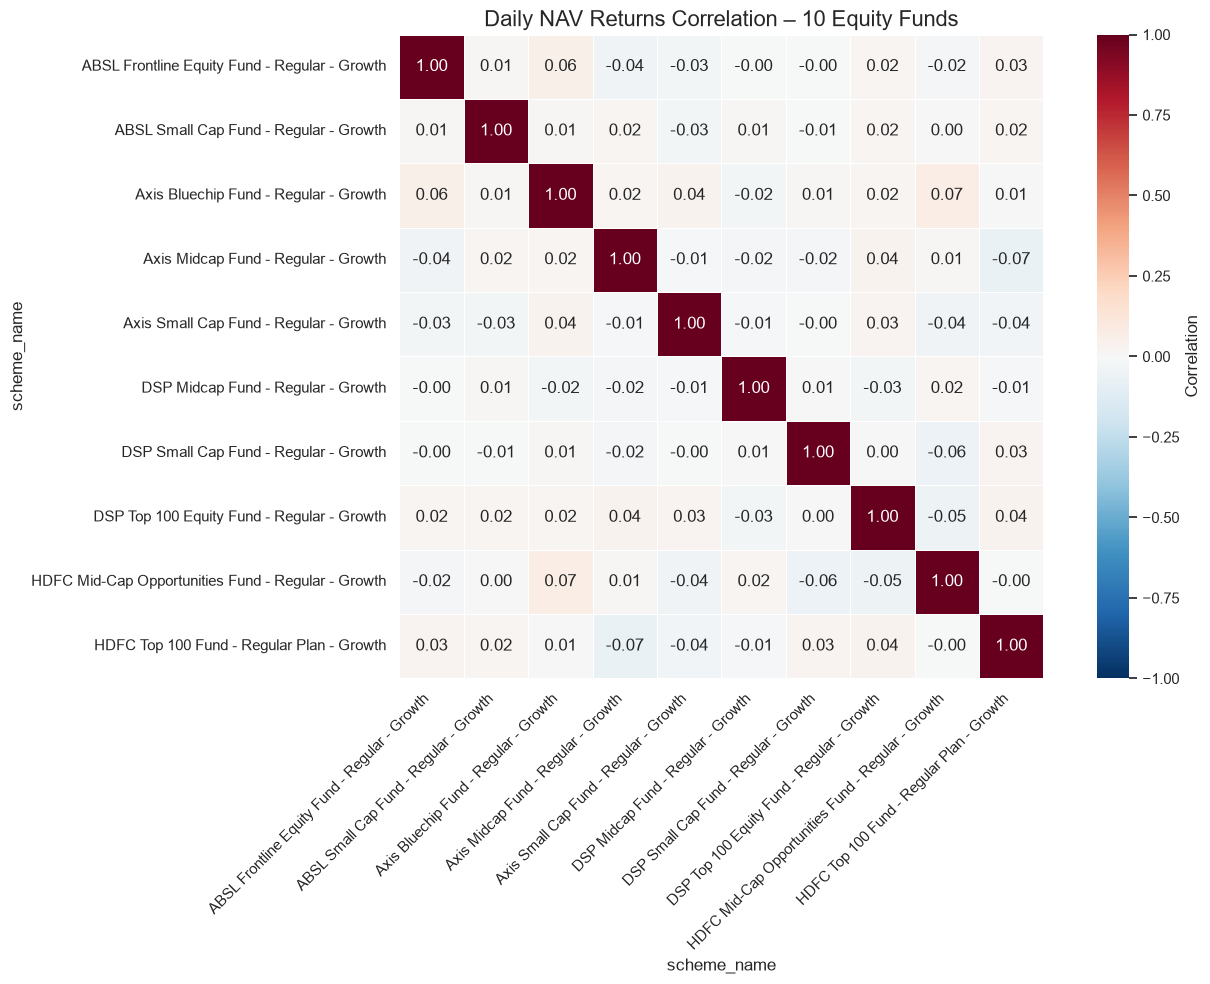

In [46]:
# NAV Returns Correlation Heatmap

plt.figure(figsize=(14, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="RdBu_r",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    square=True,
    cbar_kws={"label": "Correlation"}
)

plt.title("Daily NAV Returns Correlation – 10 Equity Funds", fontsize=16)
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()

plt.show()

In [47]:
# Save NAV Returns Correlation Heatmap
plt.savefig(
    "reports/eda_charts/11_nav_returns_correlation.png",
    dpi=300,
    bbox_inches="tight"
)

print("NAV Returns Correlation Heatmap saved successfully!")

NAV Returns Correlation Heatmap saved successfully!


<Figure size 1200x600 with 0 Axes>

In [48]:
# Check daily returns statistics
daily_returns.describe()

scheme_name,ABSL Frontline Equity Fund - Regular - Growth,ABSL Small Cap Fund - Regular - Growth,Axis Bluechip Fund - Regular - Growth,Axis Midcap Fund - Regular - Growth,Axis Small Cap Fund - Regular - Growth,DSP Midcap Fund - Regular - Growth,DSP Small Cap Fund - Regular - Growth,DSP Top 100 Equity Fund - Regular - Growth,HDFC Mid-Cap Opportunities Fund - Regular - Growth,HDFC Top 100 Fund - Regular Plan - Growth
count,1149.000000,1149.000000,1149.000000,1149.000000,1149.000000,1149.000000,1149.000000,1149.000000,1149.000000,1149.000000
mean,0.000852,0.000424,0.000275,0.001027,0.000182,0.001055,0.001194,0.000522,0.001080,0.000142
std,0.009177,0.016251,0.008788,0.012225,0.015790,0.011179,0.015648,0.009042,0.011929,0.009164
min,-0.038121,-0.051847,-0.023383,-0.040755,-0.048367,-0.030092,-0.048870,-0.036676,-0.044238,-0.024744
25%,-0.005733,-0.010799,-0.005866,-0.006747,-0.010515,-0.006437,-0.008741,-0.005441,-0.006654,-0.006282
50%,0.000808,0.000182,0.000251,0.000613,0.000172,0.001239,0.000987,0.000432,0.001086,-0.000070
75%,0.007165,0.011286,0.006211,0.009274,0.011215,0.008945,0.011440,0.006639,0.008844,0.006523
max,0.033956,0.054851,0.033626,0.041591,0.043110,0.041995,0.048490,0.029362,0.041954,0.032145


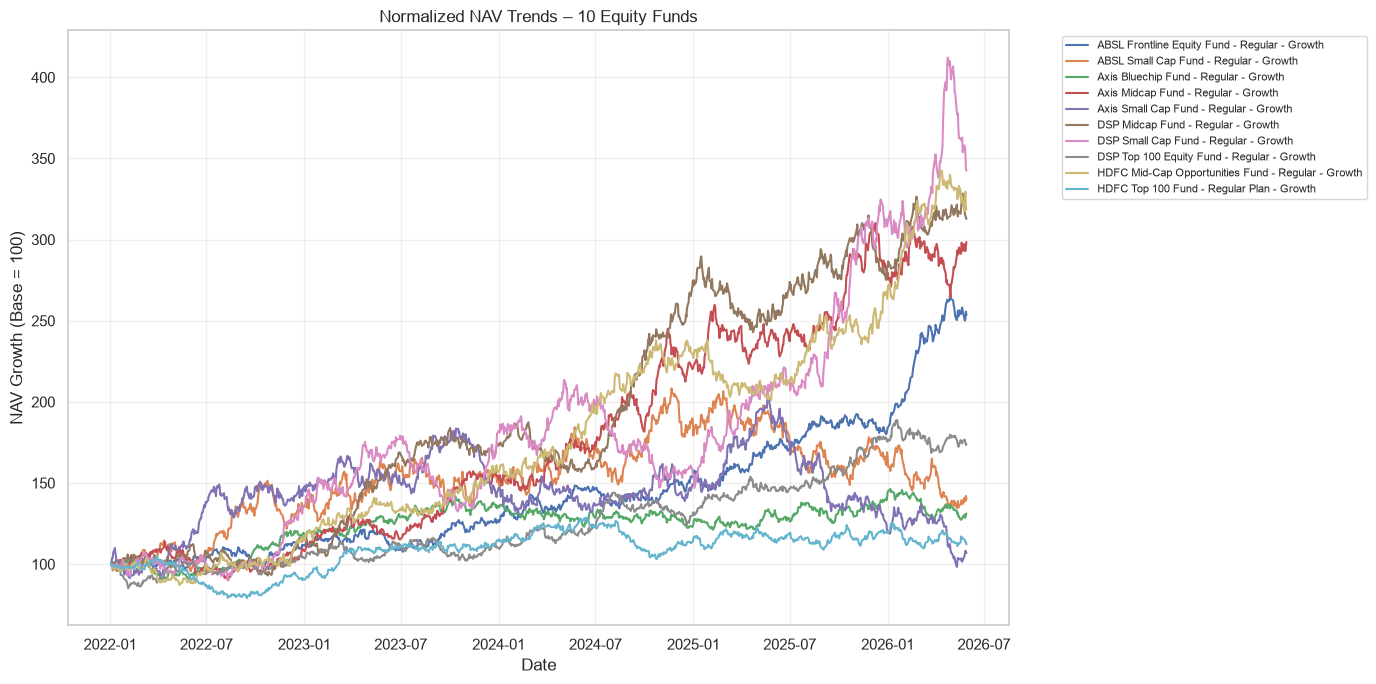

In [49]:
# Compare normalized NAV trends
normalized_nav = (nav_pivot / nav_pivot.iloc[0]) * 100

plt.figure(figsize=(14, 7))

for scheme in normalized_nav.columns:
    plt.plot(normalized_nav.index, normalized_nav[scheme], label=scheme)

plt.title("Normalized NAV Trends – 10 Equity Funds")
plt.xlabel("Date")
plt.ylabel("NAV Growth (Base = 100)")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left", fontsize=8)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [50]:
# Inspect holdings data
holdings.head(10)

NameError: name 'holdings' is not defined

In [51]:
# Check which datasets are currently available
datasets.keys()

dict_keys(['transactions', 'nav', 'fund_master', 'aum', 'sip', 'category_inflows', 'folio', 'performance', 'holdings'])

In [52]:
# Load holdings dataset
holdings = datasets["holdings"]

# Display first 10 rows
holdings.head(10)

,amfi_code,stock_symbol,stock_name,sector,weight_pct,market_value_cr,current_price_inr,portfolio_date
0,119551,POWERGRID,Power Grid Corporation,Utilities,13.85,737.09,6011.08,2025-12-31
1,119551,HDFCBANK,HDFC Bank Ltd,Banking,11.19,88.97,1074.65,2025-12-31
2,119551,GRASIM,Grasim Industries Ltd,Diversified,9.90,208.45,5964.59,2025-12-31
3,119551,DRREDDY,Dr. Reddy's Laboratories,Pharma,4.76,161.32,3748.82,2025-12-31
4,119551,ASIANPAINT,Asian Paints Ltd,Paints,10.25,725.90,1321.45,2025-12-31
5,119551,NTPC,NTPC Ltd,Utilities,7.48,897.70,2913.66,2025-12-31
6,119551,DIVISLAB,Divi's Laboratories,Pharma,3.21,286.44,3964.01,2025-12-31
7,119551,BHARTIARTL,Bharti Airtel Ltd,Telecom,13.94,452.19,5013.45,2025-12-31
8,119551,HCLTECH,HCL Technologies Ltd,IT,18.22,177.35,6024.13,2025-12-31
9,119551,MARUTI,Maruti Suzuki India Ltd,Automobile,7.20,1982.33,5461.85,2025-12-31


In [53]:
# Check the number of funds and sectors
print("Unique funds:", holdings["amfi_code"].nunique())
print("\nUnique sectors:", holdings["sector"].nunique())

print("\nSector names:")
print(sorted(holdings["sector"].unique()))

print("\nPortfolio dates:")
print(holdings["portfolio_date"].unique())

Unique funds: 34

Unique sectors: 14

Sector names:
['Automobile', 'Banking', 'Cement', 'Consumer Goods', 'Diversified', 'Energy', 'FMCG', 'IT', 'Infrastructure', 'NBFC', 'Paints', 'Pharma', 'Telecom', 'Utilities']

Portfolio dates:
<DatetimeArray>
['2025-12-31 00:00:00']
Length: 1, dtype: datetime64[us]


In [54]:
# Calculate sector allocation for each fund
sector_by_fund = (
    holdings.groupby(["amfi_code", "sector"])["weight_pct"]
    .sum()
    .unstack(fill_value=0)
)

# Normalize each fund's sector weights to 100%
sector_normalized = sector_by_fund.div(
    sector_by_fund.sum(axis=1), axis=0
) * 100

# Calculate average sector allocation across all funds
sector_allocation = sector_normalized.mean().sort_values(ascending=False)

# Display results
print("Average Sector Allocation Across 34 Funds (%)")
display(sector_allocation.round(2))

Average Sector Allocation Across 34 Funds (%)


sector
Banking           19.18
IT                13.40
Pharma            11.98
Automobile         9.52
Utilities          7.81
FMCG               6.74
Infrastructure     5.65
Diversified        4.98
Telecom            4.28
Consumer Goods     3.75
NBFC               3.50
Energy             3.47
Cement             3.09
Paints             2.64
dtype: float64

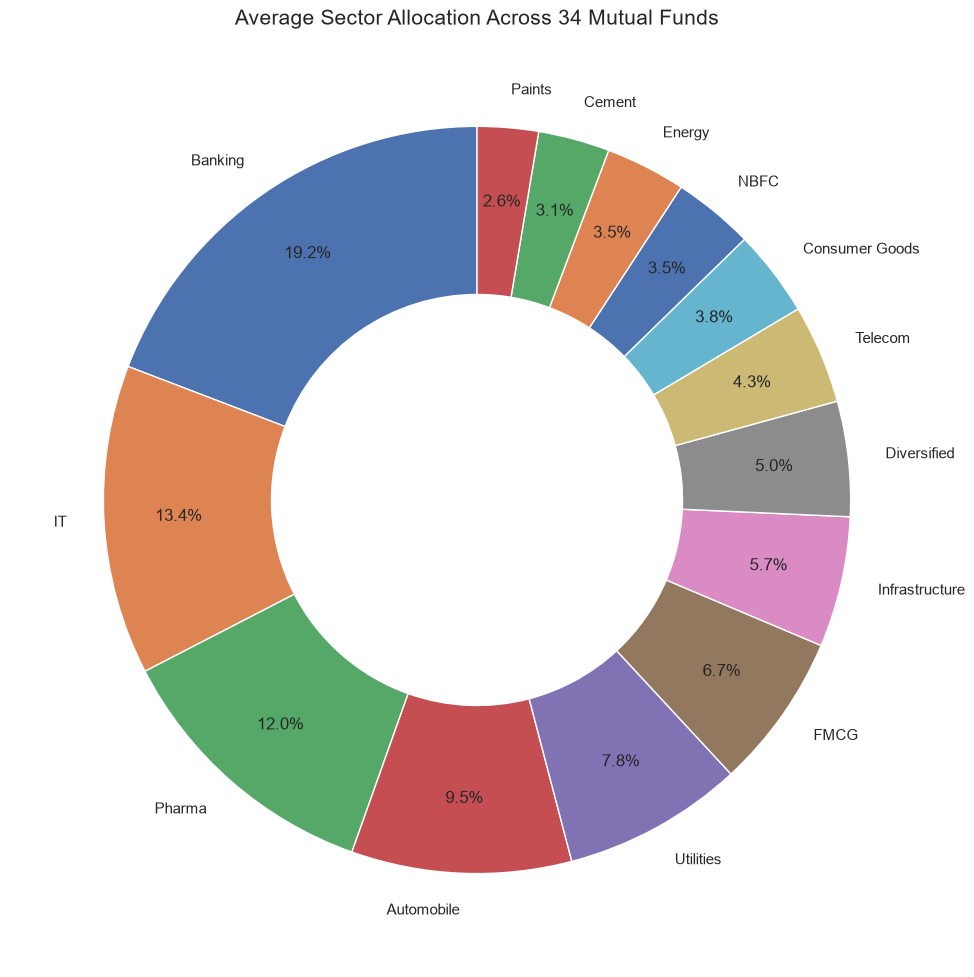

In [55]:
# Sector Allocation Donut Chart

plt.figure(figsize=(10, 10))

plt.pie(
    sector_allocation,
    labels=sector_allocation.index,
    autopct="%1.1f%%",
    startangle=90,
    pctdistance=0.80,
    wedgeprops={"width": 0.45, "edgecolor": "white"}
)

plt.title("Average Sector Allocation Across 34 Mutual Funds", fontsize=15)
plt.tight_layout()
plt.show()

In [56]:
# Save Sector Allocation Chart
plt.savefig(
    "reports/eda_charts/12_sector_allocation.png",
    dpi=300,
    bbox_inches="tight"
)

print("Sector Allocation Chart saved successfully!")

Sector Allocation Chart saved successfully!


<Figure size 1200x600 with 0 Axes>

In [58]:
# Final Exploratory Data Analysis (EDA) Insights
m
1. **NAV Trends:** Mutual fund NAVs showed varying growth patterns over the analysis period from 2022 to 2026, reflecting differences in fund performance and movement over time. *(Chart 01)*

2. **Assets Under Management (AUM):** SBI Mutual Fund recorded the highest AUM among the fund houses in the yearly comparison, with its AUM increasing from ₹6.30 lakh crore in 2022 to ₹12.50 lakh crore in 2025. *(Chart 02)*

3. **SIP Growth:** Monthly SIP inflows demonstrated a strong upward trend from 2022 to 2025, indicating increasing participation in systematic investment plans. *(Chart 03)*

4. **Category Inflows:** Liquid funds recorded significantly higher net inflows compared with several other mutual fund categories, while ELSS showed comparatively lower inflows in the analyzed period. *(Chart 04)*

5. **Investor Age Distribution:** Investors aged 26–35 accounted for the largest share of transaction records at 41.1%, followed by the 36–45 age group at 24.9%. *(Chart 05)*

6. **Investment Amount by Age:** Transaction amounts varied across age groups, with distributions containing outliers and a wide range of investment values. *(Chart 06)*

7. **Gender Distribution:** Male investors accounted for 66.5% of transaction records, while female investors accounted for 33.5%. *(Chart 07)*

8. **Geographical Distribution:** Punjab recorded the highest total transaction value at approximately ₹31.58 crore, closely followed by Tamil Nadu at ₹31.52 crore. *(Chart 08)*

9. **Folio Growth:** Total mutual fund folios increased from 13.26 crore in January 2022 to 26.12 crore in December 2025, indicating substantial growth in folio registrations over the period. *(Chart 10)*

10. **Sector Allocation:** Banking (19.18%), IT (13.40%), and Pharma (11.98%) were the top three sectors in the equal-weighted average sector allocation across 34 funds, together accounting for 44.56%. *(Chart 12)*

SyntaxError: leading zeros in decimal integer literals are not permitted; use an 0o prefix for octal integers (2762797828.py, line 3)

# Final Exploratory Data Analysis (EDA) Insights

1. **NAV Trends:** Mutual fund NAVs showed varying growth patterns over the analysis period from 2022 to 2026, reflecting differences in fund performance and movement over time. *(Chart 01)*

2. **Assets Under Management (AUM):** SBI Mutual Fund recorded the highest AUM among the fund houses in the yearly comparison, with its AUM increasing from ₹6.30 lakh crore in 2022 to ₹12.50 lakh crore in 2025. *(Chart 02)*

3. **SIP Growth:** Monthly SIP inflows demonstrated a strong upward trend from 2022 to 2025, indicating increasing participation in systematic investment plans. *(Chart 03)*

4. **Category Inflows:** Liquid funds recorded significantly higher net inflows compared with several other mutual fund categories, while ELSS showed comparatively lower inflows in the analyzed period. *(Chart 04)*

5. **Investor Age Distribution:** Investors aged 26–35 accounted for the largest share of transaction records at 41.1%, followed by the 36–45 age group at 24.9%. *(Chart 05)*

6. **Investment Amount by Age:** Transaction amounts varied across age groups, with distributions containing outliers and a wide range of investment values. *(Chart 06)*

7. **Gender Distribution:** Male investors accounted for 66.5% of transaction records, while female investors accounted for 33.5%. *(Chart 07)*

8. **Geographical Distribution:** Punjab recorded the highest total transaction value at approximately ₹31.58 crore, closely followed by Tamil Nadu at ₹31.52 crore. *(Chart 08)*

9. **Folio Growth:** Total mutual fund folios increased from 13.26 crore in January 2022 to 26.12 crore in December 2025, indicating substantial growth in folio registrations over the period. *(Chart 10)*

10. **Sector Allocation:** Banking (19.18%), IT (13.40%), and Pharma (11.98%) were the top three sectors in the equal-weighted average sector allocation across 34 funds, together accounting for 44.56%. *(Chart 12)*

In [59]:
from pathlib import Path

chart_folder = Path("reports/eda_charts")

chart_files = sorted(chart_folder.glob("*.png"))

print("Total exported charts:", len(chart_files))
print("\nChart files:")

for file in chart_files:
    print(file.name)

Total exported charts: 12

Chart files:
01_nav_trends.png
02_aum_growth.png
03_sip_inflow_trends.png
04_category_inflow_heatmap.png
05_age_distribution.png
06_investment_by_age.png
07_gender_distribution.png
08_statewise_investment.png
09_city_tier_distribution.png
10_folio_growth.png
11_nav_returns_correlation.png
12_sector_allocation.png


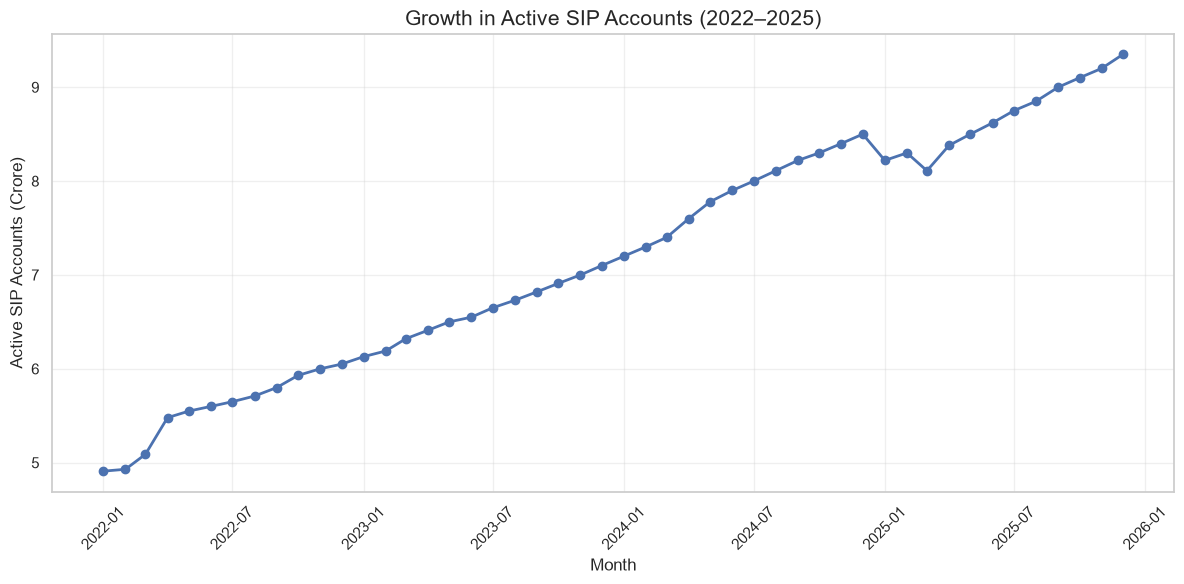

In [60]:
# Chart 13: Active SIP Accounts Growth

sip_df = datasets["sip"].copy()

plt.figure(figsize=(12, 6))

plt.plot(
    sip_df["month"],
    sip_df["active_sip_accounts_crore"],
    marker="o",
    linewidth=2
)

plt.title("Growth in Active SIP Accounts (2022–2025)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("Active SIP Accounts (Crore)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [61]:
# Save Chart 13: Active SIP Accounts Growth

plt.savefig(
    "reports/eda_charts/13_sip_account_growth.png",
    dpi=300,
    bbox_inches="tight"
)

print("Chart 13 saved successfully!")

Chart 13 saved successfully!


<Figure size 1200x600 with 0 Axes>

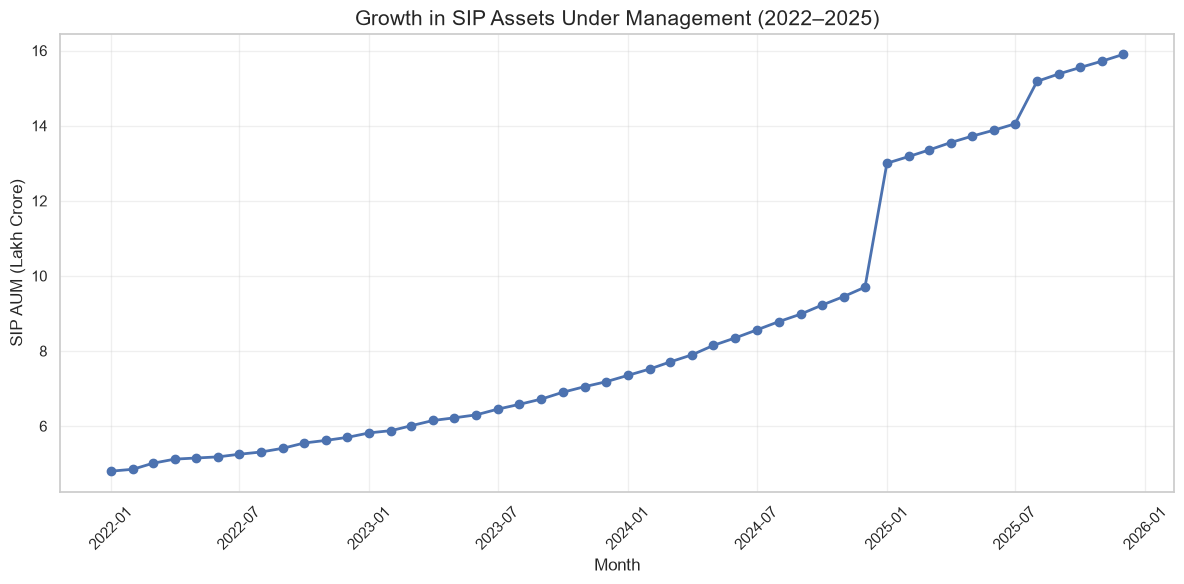

In [62]:
# Chart 14: SIP AUM Growth

plt.figure(figsize=(12, 6))

plt.plot(
    sip_df["month"],
    sip_df["sip_aum_lakh_crore"],
    marker="o",
    linewidth=2
)

plt.title("Growth in SIP Assets Under Management (2022–2025)", fontsize=15)
plt.xlabel("Month")
plt.ylabel("SIP AUM (Lakh Crore)")
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [63]:
# Save Chart 14: SIP AUM Growth

plt.savefig(
    "reports/eda_charts/14_sip_aum_growth.png",
    dpi=300,
    bbox_inches="tight"
)

print("Chart 14 saved successfully!")

Chart 14 saved successfully!


<Figure size 1200x600 with 0 Axes>

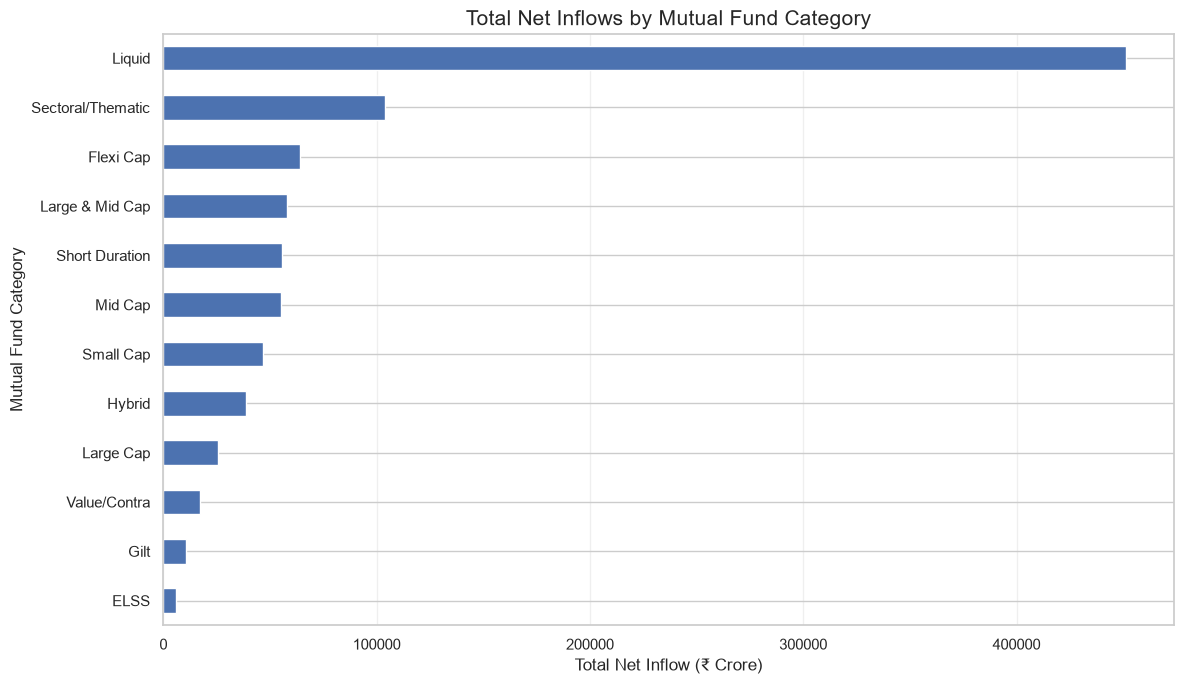

In [64]:
# Chart 15: Total Mutual Fund Category Inflows

category_totals = (
    datasets["category_inflows"]
    .groupby("category")["net_inflow_crore"]
    .sum()
    .sort_values(ascending=True)
)

plt.figure(figsize=(12, 7))

category_totals.plot(kind="barh", figsize=(12, 7))

plt.title("Total Net Inflows by Mutual Fund Category", fontsize=15)
plt.xlabel("Total Net Inflow (₹ Crore)")
plt.ylabel("Mutual Fund Category")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

In [65]:
# Save Chart 15: Category Inflow Comparison

plt.savefig(
    "reports/eda_charts/15_category_total_inflows.png",
    dpi=300,
    bbox_inches="tight"
)

print("Chart 15 saved successfully!")

Chart 15 saved successfully!


<Figure size 1200x600 with 0 Axes>

In [66]:
from pathlib import Path

chart_folder = Path("reports/eda_charts")
chart_files = sorted(chart_folder.glob("*.png"))

print(f"Total charts: {len(chart_files)}")
print("-" * 40)

for file in chart_files:
    print(f"✓ {file.name}")

Total charts: 15
----------------------------------------
✓ 01_nav_trends.png
✓ 02_aum_growth.png
✓ 03_sip_inflow_trends.png
✓ 04_category_inflow_heatmap.png
✓ 05_age_distribution.png
✓ 06_investment_by_age.png
✓ 07_gender_distribution.png
✓ 08_statewise_investment.png
✓ 09_city_tier_distribution.png
✓ 10_folio_growth.png
✓ 11_nav_returns_correlation.png
✓ 12_sector_allocation.png
✓ 13_sip_account_growth.png
✓ 14_sip_aum_growth.png
✓ 15_category_total_inflows.png
